In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
import dask.dataframe as dd


In [2]:
rc_default = {}
rc_default['font.family'] = 'serif'
rc_default['font.size'] = 24
rc_default['axes.labelsize'] = 30
rc_default['axes.labelweight'] = 'normal'
rc_default['axes.linewidth'] = 1.0
rc_default['axes.titlesize'] = 30
rc_default['xtick.labelsize'] = 30
rc_default['ytick.labelsize'] = 30
rc_default['legend.fontsize'] = 24
rc_default['figure.titlesize'] = 24
rc_default['savefig.dpi'] = 100

rc_default['xtick.major.size'] = 10
rc_default['xtick.major.width'] = 1
rc_default['xtick.minor.size'] = 10
rc_default['xtick.minor.width'] = 0

# Latex related
rc_default['text.usetex'] = True
# rc_default['mathtext.fontset'] = 'custom'
# rc_default['mathtext.rm'] = 'Bitstream Vera Sans'
# rc_default['mathtext.it'] = 'Bitstream Vera Sans:italic'
# rc_default['mathtext.bf'] = 'Bitstream Vera Sans:bold'

plt.rcParams.update(rc_default)
plt.style.use('tableau-colorblind10')


In [3]:
import numpy as np
import pandas as pd
from astropy.table import Table
import sys
import os
sys.path.insert(0, os.path.abspath('..'))
from astropy.coordinates import SkyCoord
from astropy import units as u
import warnings
import util

warnings.filterwarnings('ignore')
from astropy.io import fits
import healpy as hp
import utils


In [4]:
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

In [146]:
gaia_path = '/its/home/bb345/5-4most_data/other_data/gaia_sources/19769.parquet'
# gaia = pd.read_parquet(gaia_path)

In [147]:
df = dd.read_parquet(gaia_path, engine="pyarrow")


In [148]:
print(df.head())  # Loads only a small part


          ra        dec  phot_bp_mean_mag  phot_g_mean_mag  phot_rp_mean_mag
0  69.885881 -74.913928         21.051025        20.925083         19.776978
1  69.491265 -74.954954         21.023272        20.756933         20.672010
2  69.185615 -74.793892         20.030766        19.454926         18.799538
3  68.712826 -74.835657         19.319050        18.844809         18.229519
4  64.365958 -74.910036         20.489437        19.368704         18.338200


In [149]:
df.columns.tolist()

['ra', 'dec', 'phot_bp_mean_mag', 'phot_g_mean_mag', 'phot_rp_mean_mag']

In [150]:
filtered_df_2 = df[df['phot_bp_mean_mag']<16]

In [151]:
gaia = filtered_df_2.compute()  # Triggers computation and loads into memory

In [152]:
gaia

,ra,dec,phot_bp_mean_mag,phot_g_mean_mag,phot_rp_mean_mag
111,29.888828,-74.166450,14.989807,14.312305,13.525352
115,31.393814,-73.911196,12.323232,11.987258,11.485638
163,40.511222,-74.182652,15.066932,14.715725,14.199784
171,46.482523,-74.092098,15.295508,14.919883,14.381253
184,43.417346,-73.545977,12.640541,12.110338,11.430513
...,...,...,...,...,...
5337712,254.287977,-20.308886,15.700665,14.836526,13.921988
5337771,249.959917,-21.098872,15.606976,14.835781,13.969307
5337833,251.048515,-20.556058,15.757524,15.025962,14.188132
5337857,250.123569,-20.623537,14.442472,13.926826,13.246004


In [153]:
bg_path = '/its/home/bb345/5-4most_data/CRS/target_catalogues/BG/full_legacy_no_colour_sel/reduced/crs_sel/crs_bg_selection_crs_foot_both_nomaskbit.fits'

In [154]:
bg = Table.read(bg_path)
bg = bg.to_pandas()

In [155]:
BG = bg

In [156]:
import utils


In [157]:
crs_foot_mask = utils.get_4most_s8foot(gaia['ra'], gaia['dec'])

In [158]:
gaia = gaia[crs_foot_mask]

In [159]:
gaia

,ra,dec,phot_bp_mean_mag,phot_g_mean_mag,phot_rp_mean_mag
346,37.554330,-70.486843,14.168434,13.853745,13.379616
376,47.818738,-70.197913,11.574349,10.882074,10.077030
386,45.817339,-69.212018,15.399928,15.233818,14.627497
397,41.414365,-70.272093,15.323692,14.988723,14.473020
398,42.306985,-70.429639,15.503103,15.153401,14.624284
...,...,...,...,...,...
5083257,166.711902,-20.082081,15.382015,14.906071,14.271135
5083259,160.172849,-21.854031,12.283640,11.876096,11.291032
5083260,160.413468,-21.707730,14.635467,14.301862,13.808414
5083274,160.916626,-20.690861,14.782573,14.437469,13.920956


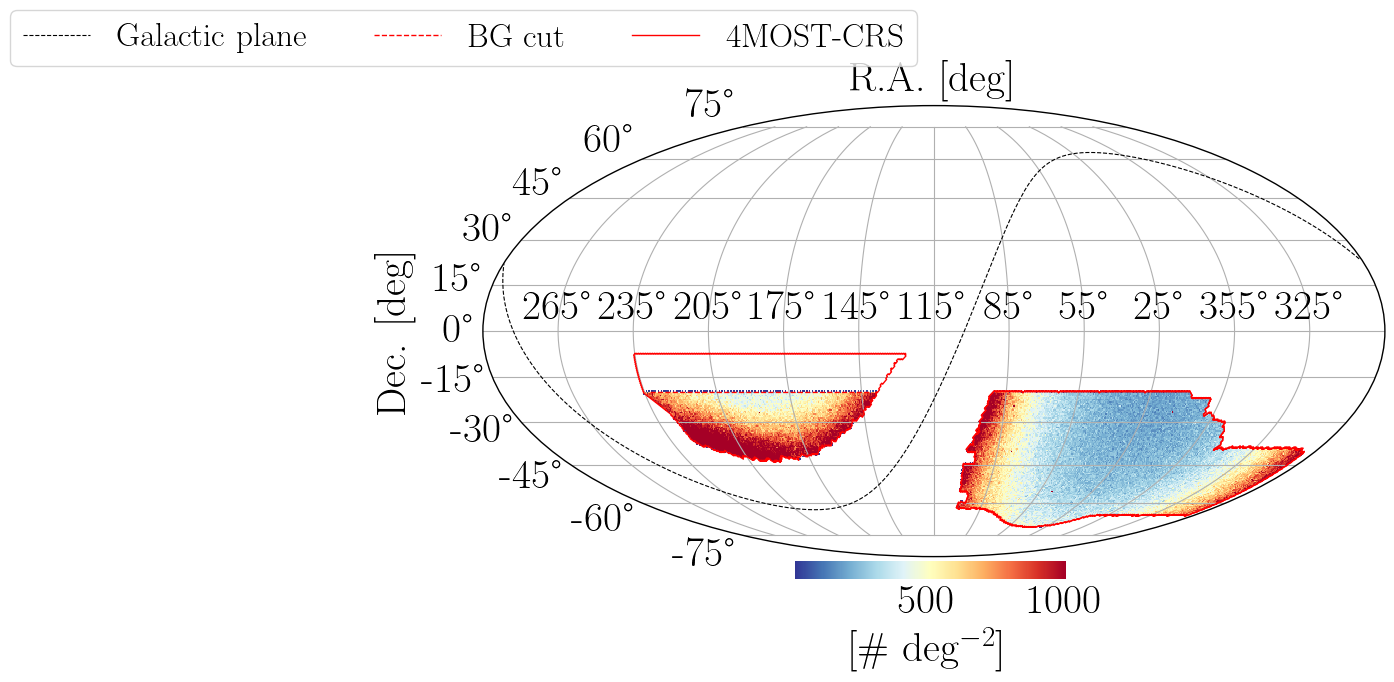

In [160]:
hpmap = utils.create_hp_map(gaia['ra'], gaia['dec'], nside=128)
utils.plot_moll(hpmap, rot=115, min=30, max=1000, fourmost_footprint=True)

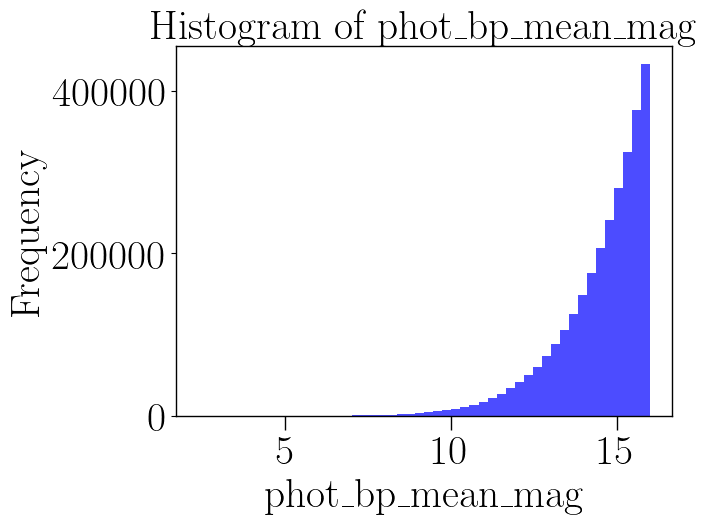

In [161]:
import matplotlib.pyplot as plt

plt.hist(gaia['phot_bp_mean_mag'], bins=50, color='blue', alpha=0.7)
plt.xlabel('phot_bp_mean_mag')
plt.ylabel('Frequency')
plt.title('Histogram of phot_bp_mean_mag')
plt.show()

In [162]:
bg

,OBJID,RA,DEC,EBV,WISEMASK_W1,MASKBITS,isBG_4M,in_S8,in_DESI_DR1,mag_r,mag_z,mag_g,mag_i,mag_w1,isBG_4M_v2,desi_bgs_selection,galactic_cap,dr1_bg_mask
0,502,61.864164,-48.102204,0.014650,0,0,True,True,False,18.896099,18.056356,20.478117,18.349930,17.650604,True,True,b'SGC',False
1,1085,61.873766,-48.022694,0.014376,0,0,True,True,False,18.582161,17.871901,19.800209,18.132414,17.555096,True,True,b'SGC',False
2,1761,61.885109,-47.882649,0.013249,0,65536,True,True,False,18.683809,18.036644,19.971437,18.269945,17.931900,True,True,b'SGC',False
3,1848,61.886476,-47.898439,0.013470,0,65536,True,True,False,18.364119,17.642792,19.513239,17.907314,17.596020,True,True,b'SGC',False
4,2147,61.891984,-47.875165,0.013068,0,65536,False,True,False,19.217236,18.412218,20.649858,18.709866,18.147125,True,True,b'SGC',False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537679,3593,221.873529,-21.003616,0.114499,0,0,True,True,False,17.683083,16.998205,18.762459,17.299942,17.120102,True,True,b'NGC',False
1537680,3647,221.875748,-20.923997,0.114941,0,0,True,True,False,18.463263,17.743073,19.882755,18.020517,17.569988,True,True,b'NGC',False
1537681,4405,221.904949,-21.047089,0.115371,0,0,True,True,False,18.307981,17.445019,20.053410,17.750391,17.005470,True,True,b'NGC',False
1537682,4479,221.908058,-21.047307,0.115419,0,0,False,True,False,19.116163,18.171936,20.902779,18.500757,17.514915,True,True,b'NGC',False


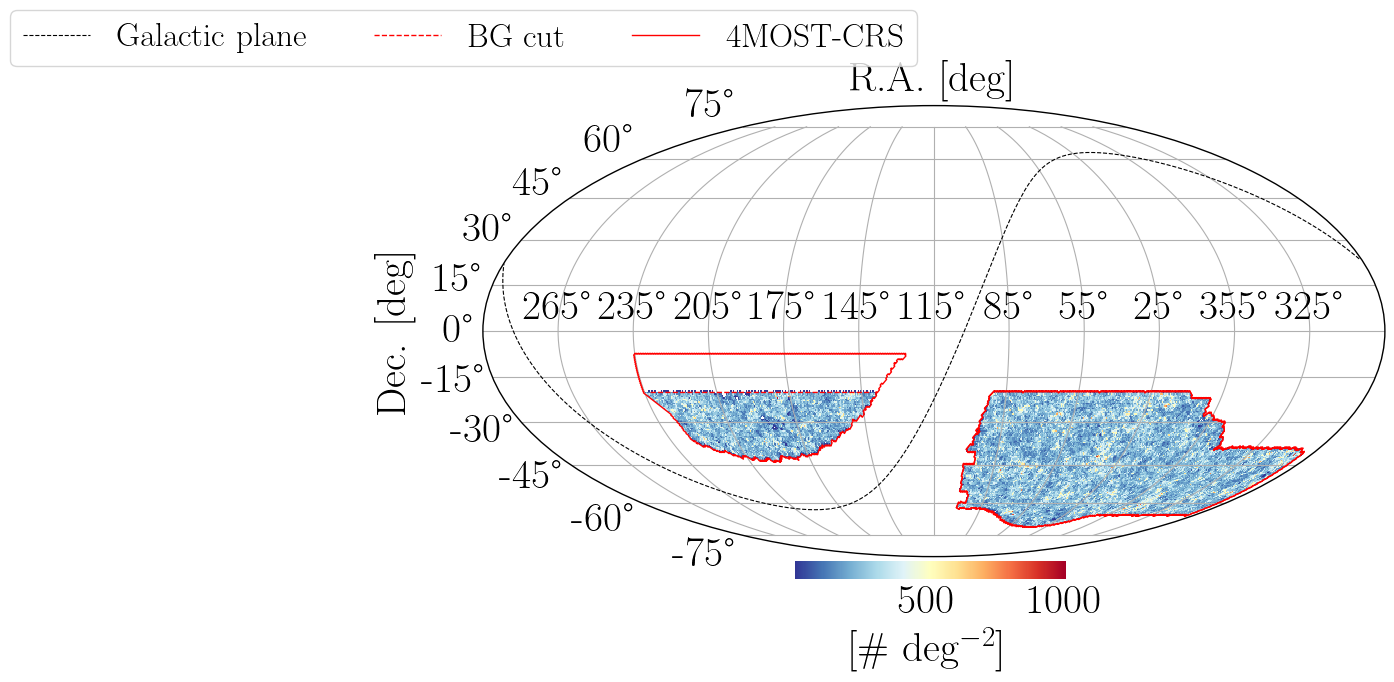

In [163]:
hpmap = utils.create_hp_map(bg['RA'], bg['DEC'], nside=128)
utils.plot_moll(hpmap, rot=115, min=30, max=1000, fourmost_footprint=True)

In [164]:
sel = bg['MASKBITS'] & 2**1 > 0
sel_11 = bg['MASKBITS'] & 2**11 > 0

In [165]:
bg_masked_areas = bg[sel]
bg_masked_areas_11 = bg[sel_11]

In [166]:
bg_masked = bg[~sel_11]

In [167]:
bg_masked_areas

,OBJID,RA,DEC,EBV,WISEMASK_W1,MASKBITS,isBG_4M,in_S8,in_DESI_DR1,mag_r,mag_z,mag_g,mag_i,mag_w1,isBG_4M_v2,desi_bgs_selection,galactic_cap,dr1_bg_mask
125,17720,63.064765,-48.814430,0.017355,163,2834,True,True,False,17.261265,16.591793,18.619225,17.150633,NaN,True,True,b'SGC',False
275,2270,62.381858,-47.431364,0.012199,161,19218,True,True,False,17.237259,16.707382,18.284185,16.881626,11.656985,True,True,b'SGC',False
1169,7013,63.764478,-48.228205,0.015431,35,2818,False,True,False,19.248701,18.733341,20.346087,19.421989,NaN,True,True,b'SGC',False
1207,5490,63.455811,-48.108316,0.015217,163,2818,True,True,False,18.442993,17.508877,19.910032,18.185459,NaN,True,True,b'SGC',False
1497,6612,63.164908,-45.369472,0.028737,163,2818,True,True,False,17.594025,17.086325,18.672173,17.331718,10.196276,True,True,b'SGC',False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1536763,759,221.812488,-21.319618,0.102802,163,2818,False,True,False,19.158245,18.281261,20.462255,18.796700,NaN,True,True,b'NGC',False
1536868,1039,220.965689,-21.108604,0.098565,33,2818,True,True,False,18.859470,17.885893,20.532036,18.234932,15.345082,True,True,b'NGC',False
1537041,3233,221.146587,-22.255956,0.093364,35,19218,True,True,False,17.459709,16.817444,18.618788,17.097576,11.347140,True,True,b'NGC',False
1537162,2507,221.332925,-23.949775,0.125294,32,2818,False,True,False,19.230610,18.540012,20.700453,18.775642,17.375586,True,True,b'NGC',False


In [168]:
bg_masked_areas_11

,OBJID,RA,DEC,EBV,WISEMASK_W1,MASKBITS,isBG_4M,in_S8,in_DESI_DR1,mag_r,mag_z,mag_g,mag_i,mag_w1,isBG_4M_v2,desi_bgs_selection,galactic_cap,dr1_bg_mask
41,7057,62.800408,-46.838704,0.012479,0,2048,True,True,False,18.923359,18.134056,20.447227,18.427818,17.927773,True,True,b'SGC',False
125,17720,63.064765,-48.814430,0.017355,163,2834,True,True,False,17.261265,16.591793,18.619225,17.150633,NaN,True,True,b'SGC',False
140,14199,62.788991,-49.288525,0.014105,0,2048,False,True,False,19.016918,18.182339,20.419220,18.516315,18.112974,True,True,b'SGC',False
202,1330,62.651397,-45.559756,0.013685,0,2048,True,True,False,18.920227,18.007906,20.796986,18.319513,17.483124,True,True,b'SGC',False
204,3461,62.726262,-45.414841,0.014417,32,2816,False,True,False,19.145117,18.401590,20.499290,18.668814,18.367283,True,True,b'SGC',False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537595,244,221.150506,-22.648268,0.094189,0,2048,True,True,False,18.937193,18.237820,20.247776,18.511284,18.171471,True,True,b'NGC',False
1537600,2412,221.236072,-22.719884,0.095946,0,2048,True,True,False,18.486904,17.756783,19.815823,18.072819,18.220806,True,True,b'NGC',False
1537633,3400,221.633934,-20.270887,0.090203,0,2048,True,True,False,18.879454,18.046806,20.258207,18.363205,17.590679,True,True,b'NGC',False
1537655,6040,221.809048,-23.236649,0.110177,0,2048,True,True,False,18.509800,17.727463,19.950893,18.029781,17.731014,True,True,b'NGC',False


In [169]:
bg_masked

,OBJID,RA,DEC,EBV,WISEMASK_W1,MASKBITS,isBG_4M,in_S8,in_DESI_DR1,mag_r,mag_z,mag_g,mag_i,mag_w1,isBG_4M_v2,desi_bgs_selection,galactic_cap,dr1_bg_mask
0,502,61.864164,-48.102204,0.014650,0,0,True,True,False,18.896099,18.056356,20.478117,18.349930,17.650604,True,True,b'SGC',False
1,1085,61.873766,-48.022694,0.014376,0,0,True,True,False,18.582161,17.871901,19.800209,18.132414,17.555096,True,True,b'SGC',False
2,1761,61.885109,-47.882649,0.013249,0,65536,True,True,False,18.683809,18.036644,19.971437,18.269945,17.931900,True,True,b'SGC',False
3,1848,61.886476,-47.898439,0.013470,0,65536,True,True,False,18.364119,17.642792,19.513239,17.907314,17.596020,True,True,b'SGC',False
4,2147,61.891984,-47.875165,0.013068,0,65536,False,True,False,19.217236,18.412218,20.649858,18.709866,18.147125,True,True,b'SGC',False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537679,3593,221.873529,-21.003616,0.114499,0,0,True,True,False,17.683083,16.998205,18.762459,17.299942,17.120102,True,True,b'NGC',False
1537680,3647,221.875748,-20.923997,0.114941,0,0,True,True,False,18.463263,17.743073,19.882755,18.020517,17.569988,True,True,b'NGC',False
1537681,4405,221.904949,-21.047089,0.115371,0,0,True,True,False,18.307981,17.445019,20.053410,17.750391,17.005470,True,True,b'NGC',False
1537682,4479,221.908058,-21.047307,0.115419,0,0,False,True,False,19.116163,18.171936,20.902779,18.500757,17.514915,True,True,b'NGC',False


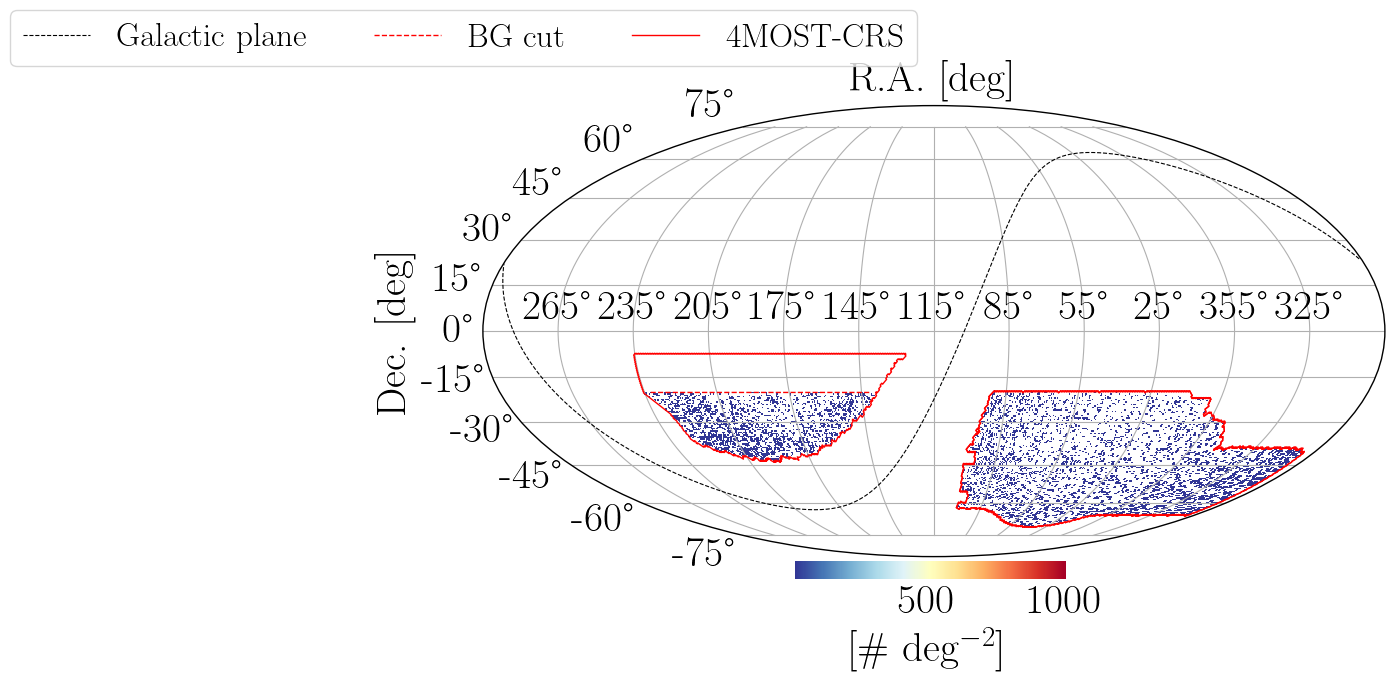

In [170]:
hpmap = utils.create_hp_map(bg_masked_areas['RA'], bg_masked_areas['DEC'], nside=128)
utils.plot_moll(hpmap, rot=115, min=30, max=1000, fourmost_footprint=True)

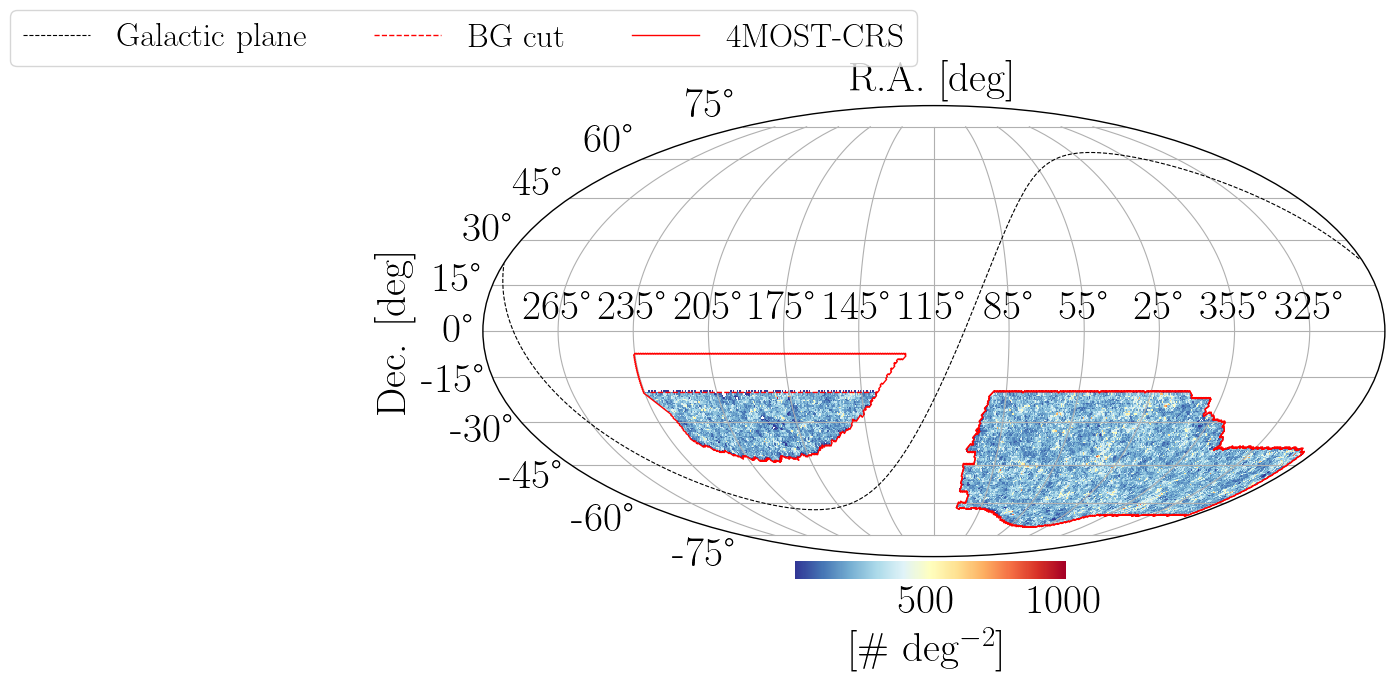

In [171]:
hpmap = utils.create_hp_map(bg_masked['RA'], bg_masked['DEC'], nside=128)
utils.plot_moll(hpmap, rot=115, min=30, max=1000, fourmost_footprint=True)

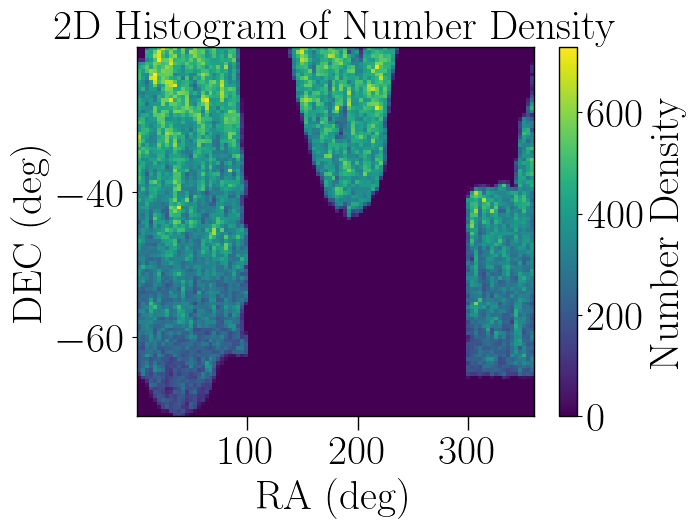

In [172]:
# Convert bg and gaia coordinates to SkyCoord objects
bg_coords = SkyCoord(ra=bg['RA'].values * u.deg, dec=bg['DEC'].values * u.deg)
gaia_coords = SkyCoord(ra=gaia['ra'].values * u.deg, dec=gaia['dec'].values * u.deg)

# Find separations and filter within 1-degree radius
idx, sep2d, _ = bg_coords.match_to_catalog_sky(gaia_coords)
mask_within_1deg = sep2d < 1 * u.deg

# Create a 2D histogram
plt.hist2d(bg['RA'][mask_within_1deg], bg['DEC'][mask_within_1deg], bins=100, cmap='viridis')
plt.colorbar(label='Number Density')
plt.xlabel('RA (deg)')
plt.ylabel('DEC (deg)')
plt.title('2D Histogram of Number Density')
plt.show()

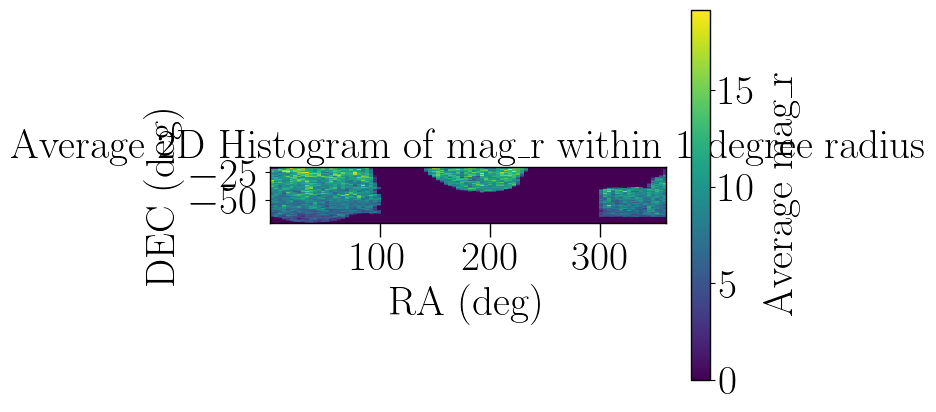

In [173]:
# Filter bg coordinates within 1-degree radius
bg_within_1deg = bg[mask_within_1deg]

# Create a 2D histogram with average values
hist, xedges, yedges, binnumber = plt.hist2d(
    bg_within_1deg['RA'], bg_within_1deg['DEC'], bins=100, cmap='viridis', weights=bg_within_1deg['mag_r']
)
counts, _, _, _ = plt.hist2d(
    bg_within_1deg['RA'], bg_within_1deg['DEC'], bins=100, cmap='viridis'
)

# Avoid division by zero
average_hist = np.divide(hist, counts, out=np.zeros_like(hist), where=counts != 0)

# Plot the average 2D histogram
plt.imshow(
    average_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], cmap='viridis'
)
plt.colorbar(label='Average mag_r')
plt.xlabel('RA (deg)')
plt.ylabel('DEC (deg)')
plt.title('Average 2D Histogram of mag_r within 1-degree radius')
plt.show()

In [174]:
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


In [175]:
gaia

,ra,dec,phot_bp_mean_mag,phot_g_mean_mag,phot_rp_mean_mag
346,37.554330,-70.486843,14.168434,13.853745,13.379616
376,47.818738,-70.197913,11.574349,10.882074,10.077030
386,45.817339,-69.212018,15.399928,15.233818,14.627497
397,41.414365,-70.272093,15.323692,14.988723,14.473020
398,42.306985,-70.429639,15.503103,15.153401,14.624284
...,...,...,...,...,...
5083257,166.711902,-20.082081,15.382015,14.906071,14.271135
5083259,160.172849,-21.854031,12.283640,11.876096,11.291032
5083260,160.413468,-21.707730,14.635467,14.301862,13.808414
5083274,160.916626,-20.690861,14.782573,14.437469,13.920956


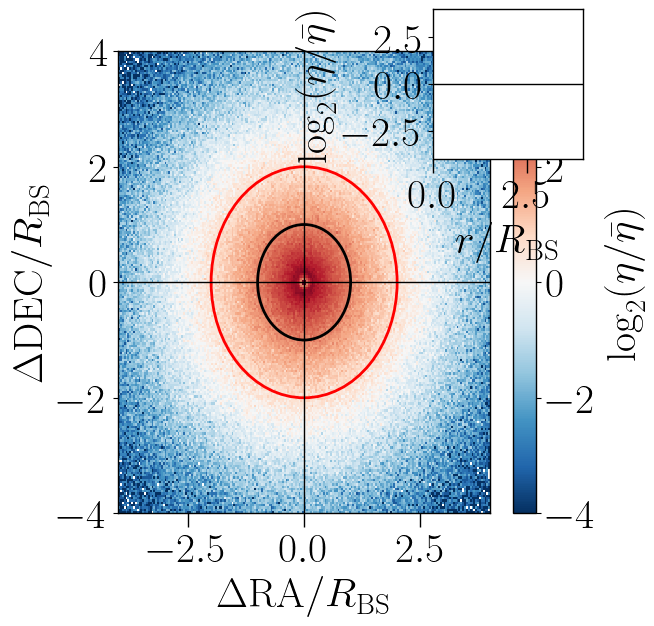

In [176]:


# 2. Select “bright” stars (e.g. G ≤ 13) and turn into SkyCoords
bright = gaia[gaia['phot_g_mean_mag'] <= 13]
stars = SkyCoord(ra=bright['ra'].values * u.deg,
                 dec=bright['dec'].values * u.deg)

# 3. Make a SkyCoord for your BG objects
cats  = SkyCoord(ra=bg['RA'].values * u.deg,
                 dec=bg['DEC'].values * u.deg)

# 4. Cross-match each BG to its nearest bright star
idx, sep2d, _ = cats.match_to_catalog_sky(stars)

# 5. Compute ΔRA, ΔDec (in the tangent-plane sense)
#    – we want small-angle approx: ΔRA_c = (RA_BG − RA_star)⋅cos(Dec_star)
ra_bg  = cats.ra.rad
dec_bg = cats.dec.rad
ra_st  = stars[idx].ra.rad
dec_st = stars[idx].dec.rad

dRA_c  = (ra_bg  - ra_st ) * np.cos(dec_st)
dDec   =  dec_bg - dec_st

# 6. Define the bright-star masking radius R_BS(m)
#    – Zarrouk et al. use a lookup or fit: e.g. RBS = f(mag)
#      here’s a toy linear example; you’ll need the real curve:
R_BS = 10**(0.2 * (13 - bright['phot_g_mean_mag'].values[idx]))  # in arcsec, say

# 7. Scale your separations by that radius
x = dRA_c  * 3600. / R_BS   # now dimensionless ΔRA/RBS
y = dDec   * 3600. / R_BS   # dimensionless ΔDec/RBS

# 8. Make a 2D histogram of (x,y)
nbins = 200
H, xe, ye = np.histogram2d(x, y, bins=nbins, range=[[-4,4],[-4,4]])
#  how to turn that into a density *ratio* η/η̄ ?
#  – compute the mean density in an annulus 1.1<R<4:
Xc, Yc = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
XX, YY = np.meshgrid(Xc,Yc)
R = np.sqrt(XX**2 + YY**2)
mask = (R>1.1) & (R<4)
eta_mean = H[mask].mean()
density_ratio = H / eta_mean

# 9. Plot
fig, ax = plt.subplots(figsize=(6,6))
pcm = ax.pcolormesh(xe, ye, np.log2(density_ratio).T,
                    cmap='RdBu_r', vmin=-4, vmax=+4)
fig.colorbar(pcm, label=r'$\log_2(\eta/\bar\eta)$')

# 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
for rad, col in [(1,'k'), (2,'r')]:
    circ = Circle((0,0), radius=rad, fill=False, ls='-', lw=2, ec=col)
    ax.add_patch(circ)

ax.set_xlim(-4,4)
ax.set_ylim(-4,4)
ax.axhline(0, color='k', lw=1)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

# 11. Compute & overplot the radial density profile
r_bins = np.linspace(0,4,80)
r_cent = 0.5*(r_bins[:-1]+r_bins[1:])
# compute annular counts
rad = np.sqrt(x**2 + y**2)
counts, _ = np.histogram(rad, bins=r_bins)
area = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
eta_r = counts / area
# normalise & log2
eta_r_norm = eta_r / eta_mean
ax2 = fig.add_axes([0.65,0.7,0.25,0.25])
ax2.plot(r_cent, np.log2(eta_r_norm), color='r')
ax2.axhline(0, color='k', lw=1)
ax2.set_xlim(0,4)
ax2.set_ylim(-4,4)
ax2.set_xlabel(r'$r/R_{\rm BS}$')
ax2.set_ylabel(r'$\log_2(\eta/\bar\eta)$')

plt.show()


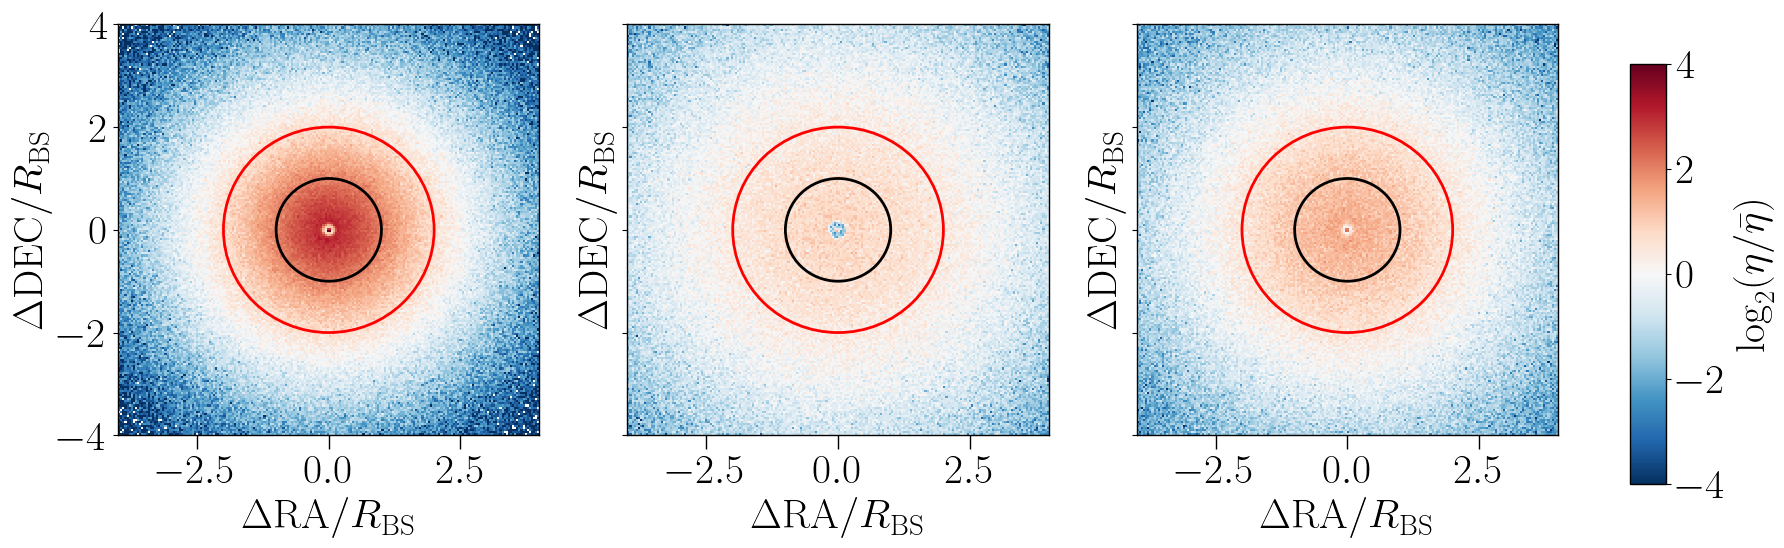

In [178]:
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# 0. Parameters
mag_bins = [(8, 12), (12, 13), (13, 16)]
nbins    = 200
r_extent = 4      # we'll plot −4 to +4 in units of R_BS
annulus   = (1.1, 4)

  # must have ['ra','dec']

# 2. Prepare BG SkyCoord
cats = SkyCoord(ra=bg['RA'].values*u.deg,
                dec=bg['DEC'].values*u.deg)

# 3. Set up figure with 3 panels
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (mag_min, mag_max) in zip(axes, mag_bins):
    # 4. Select stars in this mag bin and make SkyCoord
    sel      = (gaia['phot_g_mean_mag'] >= mag_min) & (gaia['phot_g_mean_mag'] < mag_max)
    bright   = gaia[sel]
    stars_sc = SkyCoord(ra=bright['ra'].values * u.deg,
                        dec=bright['dec'].values * u.deg)

    # 5. Cross-match BG objects to nearest bright star
    idx, sep2d, _ = cats.match_to_catalog_sky(stars_sc)

    # 6. Tangent-plane offsets ΔRA·cos(Dec), ΔDec [radians]
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars_sc[idx].ra.rad, stars_sc[idx].dec.rad
    dRA_c  = (ra_bg  - ra_st) * np.cos(dec_st)
    dDec   =  dec_bg - dec_st

    # 7. Bright-star mask radius R_BS(mag)
    #    ── Replace this toy formula with the exact DR9 prescription!
    mag_idx = bright['phot_g_mean_mag'].values[idx]
    R_BS    = 10**(0.2 * (13 - mag_idx))   # e.g. arcsec; just a placeholder

    # 8. Scale into ΔRA/R_BS, ΔDec/R_BS
    x = dRA_c  * 3600.0 / R_BS
    y = dDec   * 3600.0 / R_BS

    # 9. 2D histogram & normalised density ratio η/η̄
    H, xedges, yedges = np.histogram2d(x, y, bins=nbins,
                                       range=[[-r_extent, r_extent],
                                              [-r_extent, r_extent]])
    # compute mean density in  annulus
    Xc, Yc = 0.5*(xedges[:-1]+xedges[1:]), 0.5*(yedges[:-1]+yedges[1:])
    XX, YY = np.meshgrid(Xc, Yc)
    Rnorm  = np.sqrt(XX**2 + YY**2)
    ann_mask = (Rnorm > annulus[0]) & (Rnorm < annulus[1])
    eta_bar  = H[ann_mask].mean()
    dens_rat = H / eta_bar

    # 10. Plot the log2 density ratio
    pcm = ax.pcolormesh(xedges, yedges,
                        np.log2(dens_rat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    # ax.set_title(fr'{mag_min} ≤ G < {mag_max}')
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # 11. Overplot mask circles R=1 (DR9) in black and R≈2 (DR8) in red
    for radius, colour in [(1.0, 'k'), (2.0, 'r')]:
        circ = Circle((0,0), radius=radius,
                      fill=False, lw=2, ec=colour)
        ax.add_patch(circ)

# 12. Colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


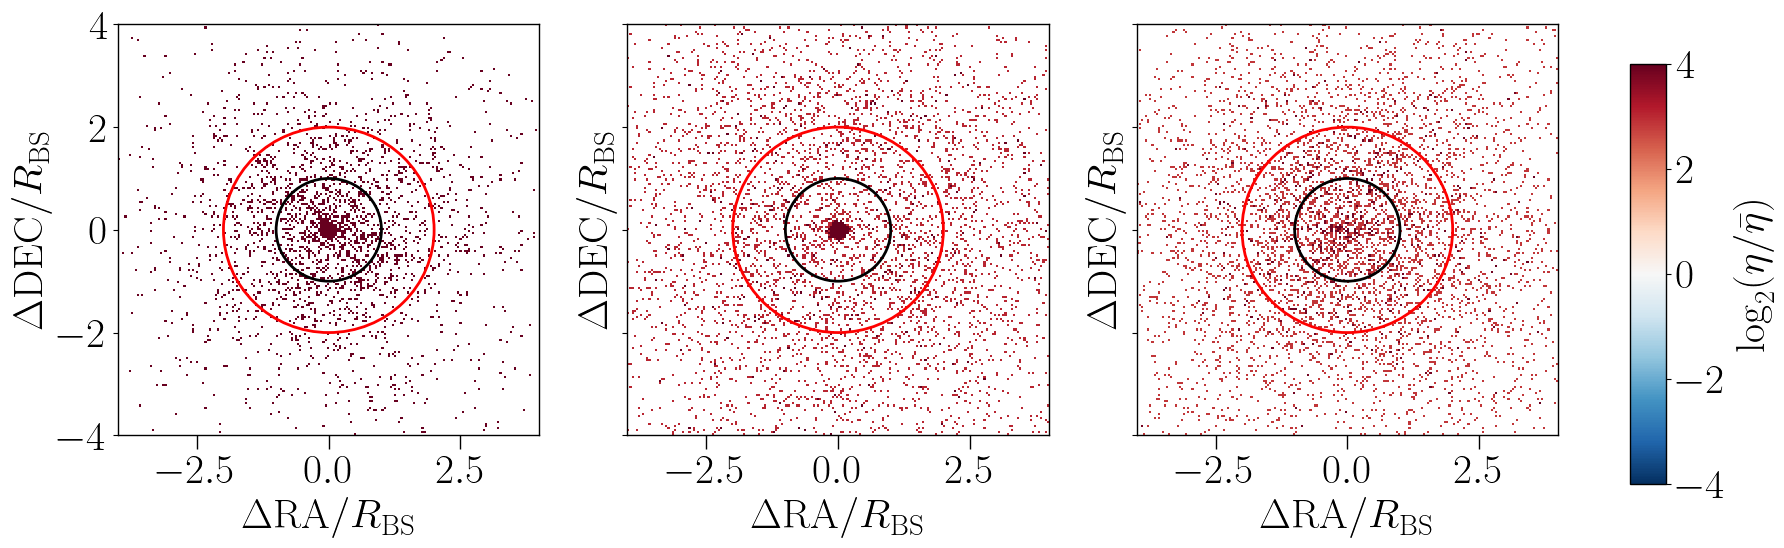

In [179]:


# 0. Parameters
mag_bins = [(8, 12), (12, 13), (13, 16)]
nbins    = 200
r_extent = 4      # we'll plot −4 to +4 in units of R_BS
annulus   = (1.1, 4)

  # must have ['ra','dec']

# 2. Prepare BG SkyCoord
cats = SkyCoord(ra=bg_masked_areas['RA'].values*u.deg,
                dec=bg_masked_areas['DEC'].values*u.deg)

# 3. Set up figure with 3 panels
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (mag_min, mag_max) in zip(axes, mag_bins):
    # 4. Select stars in this mag bin and make SkyCoord
    sel      = (gaia['phot_g_mean_mag'] >= mag_min) & (gaia['phot_g_mean_mag'] < mag_max)
    bright   = gaia[sel]
    stars_sc = SkyCoord(ra=bright['ra'].values * u.deg,
                        dec=bright['dec'].values * u.deg)

    # 5. Cross-match BG objects to nearest bright star
    idx, sep2d, _ = cats.match_to_catalog_sky(stars_sc)

    # 6. Tangent-plane offsets ΔRA·cos(Dec), ΔDec [radians]
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars_sc[idx].ra.rad, stars_sc[idx].dec.rad
    dRA_c  = (ra_bg  - ra_st) * np.cos(dec_st)
    dDec   =  dec_bg - dec_st

    # 7. Bright-star mask radius R_BS(mag)
    #    ── Replace this toy formula with the exact DR9 prescription!
    mag_idx = bright['phot_g_mean_mag'].values[idx]
    R_BS    = 10**(0.2 * (13 - mag_idx))   # e.g. arcsec; just a placeholder

    # 8. Scale into ΔRA/R_BS, ΔDec/R_BS
    x = dRA_c  * 3600.0 / R_BS
    y = dDec   * 3600.0 / R_BS

    # 9. 2D histogram & normalised density ratio η/η̄
    H, xedges, yedges = np.histogram2d(x, y, bins=nbins,
                                       range=[[-r_extent, r_extent],
                                              [-r_extent, r_extent]])
    # compute mean density in  annulus
    Xc, Yc = 0.5*(xedges[:-1]+xedges[1:]), 0.5*(yedges[:-1]+yedges[1:])
    XX, YY = np.meshgrid(Xc, Yc)
    Rnorm  = np.sqrt(XX**2 + YY**2)
    ann_mask = (Rnorm > annulus[0]) & (Rnorm < annulus[1])
    eta_bar  = H[ann_mask].mean()
    dens_rat = H / eta_bar

    # 10. Plot the log2 density ratio
    pcm = ax.pcolormesh(xedges, yedges,
                        np.log2(dens_rat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    # ax.set_title(f'{mag_min} ≤ G < {mag_max}')
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # 11. Overplot mask circles R=1 (DR9) in black and R≈2 (DR8) in red
    for radius, colour in [(1.0, 'k'), (2.0, 'r')]:
        circ = Circle((0,0), radius=radius,
                      fill=False, lw=2, ec=colour)
        ax.add_patch(circ)

# 12. Colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


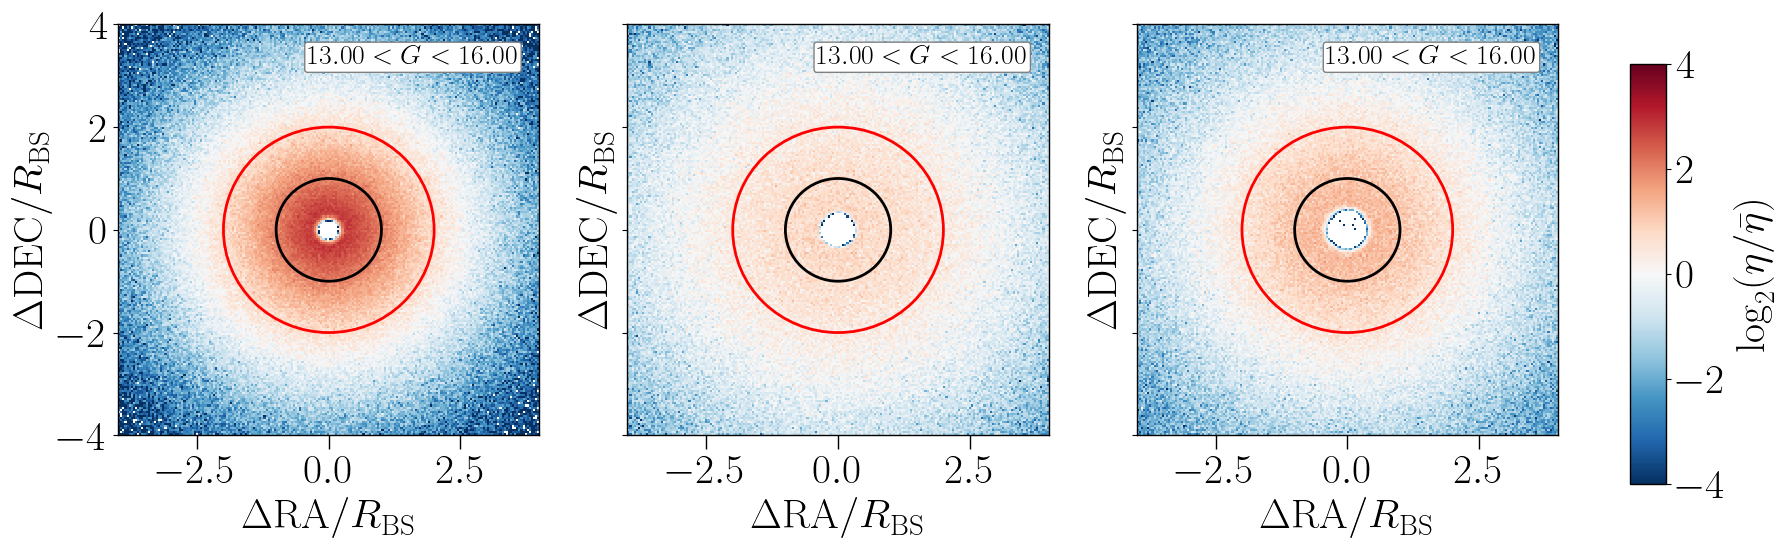

In [180]:


# 0. Parameters
mag_bins = [(8, 12), (12, 13), (13, 16)]
nbins    = 200
r_extent = 4      # we'll plot −4 to +4 in units of R_BS
annulus   = (1.1, 4)

  # must have ['ra','dec']

# 2. Prepare BG SkyCoord
cats = SkyCoord(ra=bg_masked['RA'].values*u.deg,
                dec=bg_masked['DEC'].values*u.deg)

# 3. Set up figure with 3 panels
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (mag_min, mag_max) in zip(axes, mag_bins):
    # 4. Select stars in this mag bin and make SkyCoord
    sel      = (gaia['phot_g_mean_mag'] >= mag_min) & (gaia['phot_g_mean_mag'] < mag_max)
    bright   = gaia[sel]
    stars_sc = SkyCoord(ra=bright['ra'].values * u.deg,
                        dec=bright['dec'].values * u.deg)

    # 5. Cross-match BG objects to nearest bright star
    idx, sep2d, _ = cats.match_to_catalog_sky(stars_sc)

    # 6. Tangent-plane offsets ΔRA·cos(Dec), ΔDec [radians]
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars_sc[idx].ra.rad, stars_sc[idx].dec.rad
    dRA_c  = (ra_bg  - ra_st) * np.cos(dec_st)
    dDec   =  dec_bg - dec_st

    # 7. Bright-star mask radius R_BS(mag)
    #    ── Replace this toy formula with the exact DR9 prescription!
    mag_idx = bright['phot_g_mean_mag'].values[idx]
    R_BS    = 10**(0.2 * (13 - mag_idx))   # e.g. arcsec; just a placeholder

    # 8. Scale into ΔRA/R_BS, ΔDec/R_BS
    x = dRA_c  * 3600.0 / R_BS
    y = dDec   * 3600.0 / R_BS

    # 9. 2D histogram & normalised density ratio η/η̄
    H, xedges, yedges = np.histogram2d(x, y, bins=nbins,
                                       range=[[-r_extent, r_extent],
                                              [-r_extent, r_extent]])
    # compute mean density in  annulus
    Xc, Yc = 0.5*(xedges[:-1]+xedges[1:]), 0.5*(yedges[:-1]+yedges[1:])
    XX, YY = np.meshgrid(Xc, Yc)
    Rnorm  = np.sqrt(XX**2 + YY**2)
    ann_mask = (Rnorm > annulus[0]) & (Rnorm < annulus[1])
    eta_bar  = H[ann_mask].mean()
    dens_rat = H / eta_bar
    ax.text (0.95, 0.95, fr"${gmin:4.2f}<G<{gmax:4.2f}$",
             transform=ax.transAxes, fontsize=20, verticalalignment='top',
             horizontalalignment='right', bbox=dict(facecolor='white', alpha=1, edgecolor='gray', boxstyle='round,pad=0.1'))
    # 10. Plot the log2 density ratio
    pcm = ax.pcolormesh(xedges, yedges,
                        np.log2(dens_rat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    # ax.set_title(f'{mag_min} ≤ G < {mag_max}')
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # 11. Overplot mask circles R=1 (DR9) in black and R≈2 (DR8) in red
    for radius, colour in [(1.0, 'k'), (2.0, 'r')]:
        circ = Circle((0,0), radius=radius,
                      fill=False, lw=2, ec=colour)
        ax.add_patch(circ)

# 12. Colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


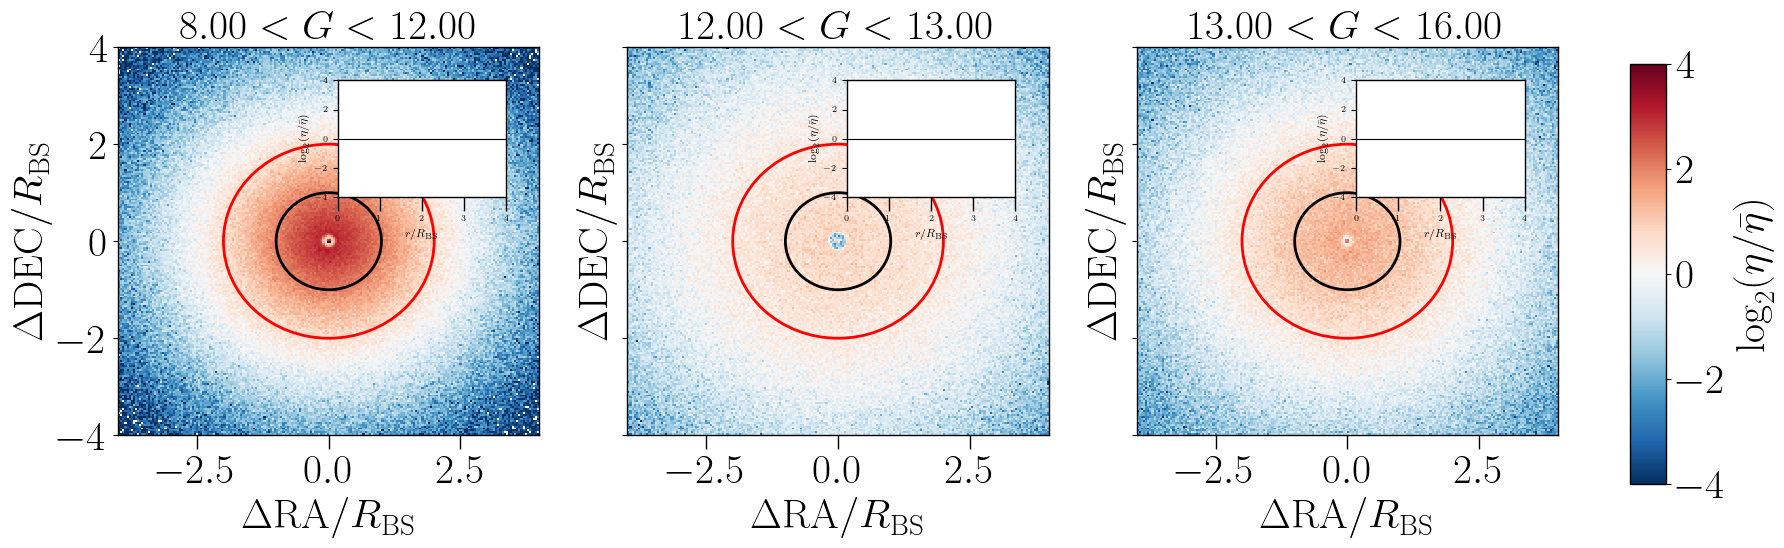

In [182]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- Parameters ---
mag_bins = [(8, 12), (12, 13), (13, 16)]
nbins    = 200
r_extent = 4.0
annulus  = (1.1, 4.0)
dr       = 0.06

# --- Prepare BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

# --- Set up figure ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # 1) select your stars in this G‐mag bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values * u.deg,
                      dec=bright['dec'].values * u.deg)

    # 2) nearest‐star match
    idx, _, _ = cats.match_to_catalog_sky(stars)

    # 3) tangent‐plane offsets
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg  - ra_st) * np.cos(dec_st)
    dDec = dec_bg - dec_st

    # 4) mask radius R_BS(mag) – **replace** with your real DR9 formula
    mags_at_idx = bright['phot_g_mean_mag'].values[idx]
    R_BS = 10**(0.2 * (13 - mags_at_idx))    # placeholder in arcsec

    # 5) scale to ΔRA/R_BS, ΔDec/R_BS
    x = dRAc * 3600.0 / R_BS
    y = dDec * 3600.0 / R_BS

    # 6) 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    XX, YY = np.meshgrid(Xc, Yc)
    Rnorm  = np.sqrt(XX**2 + YY**2)
    annmask= (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar= H[annmask].mean()
    densrat= H / eta_bar

    # 7) plot the map
    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    ax.set_title(fr"${gmin:4.2f}<G<{gmax:4.2f}$")
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # 8) overlay mask circles
    for Rcirc, col in [(1.0, 'k'), (2.0, 'r')]:
        ax.add_patch(Circle((0,0), Rcirc, fill=False, lw=2, ec=col))

    # 9) inset radial profile
    rad     = np.sqrt(x**2 + y**2)
    r_bins  = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts, _ = np.histogram(rad, bins=r_bins)
    areas     = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r     = counts / areas
    log_eta   = np.log2(eta_r / eta_bar)

    axins = inset_axes(ax, width="40%", height="30%", loc='upper right', borderpad=1)
    axins.plot(r_c, log_eta, color='r', lw=1)
    axins.axhline(0, color='k', lw=0.8)
    axins.set_xlim(0, r_extent)
    axins.set_ylim(-4, 4)
    axins.set_xlabel('$r/R_{\\rm BS}$', fontsize=8)
    axins.set_ylabel('$\log_2(\\eta/\\bar\\eta)$', fontsize=8)
    axins.tick_params(axis='both', labelsize=6)

# final colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


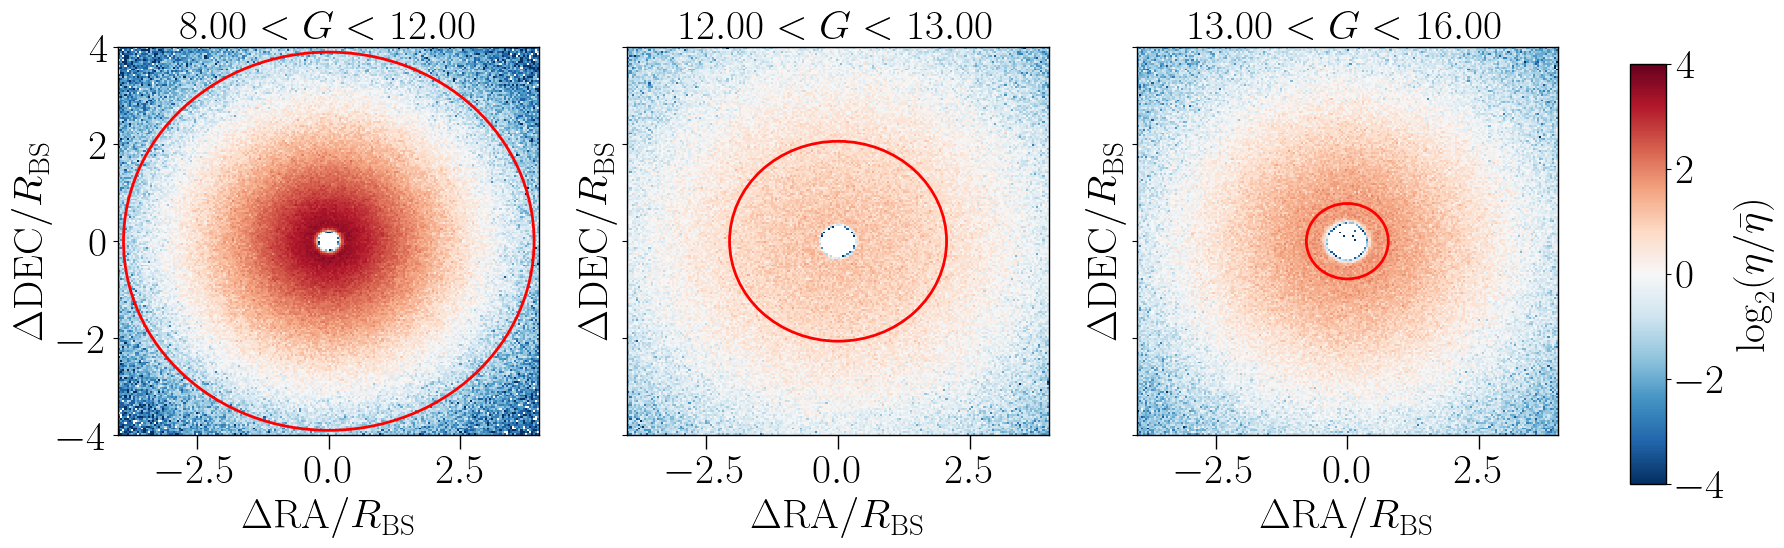

In [193]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- your existing bins & setup ---
mag_bins = [(8, 12), (12, 13), (13, 16)]
nbins    = 200
r_extent = 4.0
annulus  = (1.1, 4.0)
dr       = 0.06

# --- placeholder functions: replace with the real DR8/DR9 formulas ---
def mask_radius_DR9(g):
    # DR9 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. piecewise interpolation from Legacy Surveys DR9 prescription.
    # Here’s a toy example:
    return  10**(0.2*(13 - g))

def mask_radius_DR8(g):
    # DR8 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. a different piecewise curve published for DR8.
    # Here’s a toy example that’s ~1.7× larger than DR9:
    return 1.7 * mask_radius_DR9(g)

# --- build BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'][~sel_11].values*u.deg,
                dec=bg['DEC'][~sel_11].values*u.deg)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
for ax, (gmin, gmax) in zip(axes, mag_bins):
    # select stars in this bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values*u.deg,
                      dec=bright['dec'].values*u.deg)

    # match & compute offsets
    idx, _, _     = cats.match_to_catalog_sky(stars)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st)*np.cos(dec_st)
    dDec = dec_bg - dec_st

    # compute DR9 mask‐radii and scale
    mags_at_idx = bright['phot_g_mean_mag'].values[idx]
    R9_arcsec   = mask_radius_DR9(mags_at_idx)
    x = dRAc * 3600.0 / R9_arcsec
    y = dDec * 3600.0 / R9_arcsec

    # compute the DR8/DR9 ratio for your red circle
    R8_arcsec = mask_radius_DR8(mags_at_idx)
    red_radius = np.median(R8_arcsec)

    # 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    Rnorm    = np.sqrt(*np.meshgrid(Xc, Yc))
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    ax.set_title(fr"${gmin:4.2f}<G<{gmax:4.2f}$")
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # black DR9 circle at unity
    # ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))
    # red DR8 circle at the computed ratio
    ax.add_patch(Circle((0,0), red_radius, fill=False, lw=2, ec='r'))

    # inset radial profile…
    rad    = np.sqrt(x**2 + y**2)
    r_bins = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r    = counts/areas
    log_eta  = np.log2(eta_r/eta_bar)



# final colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


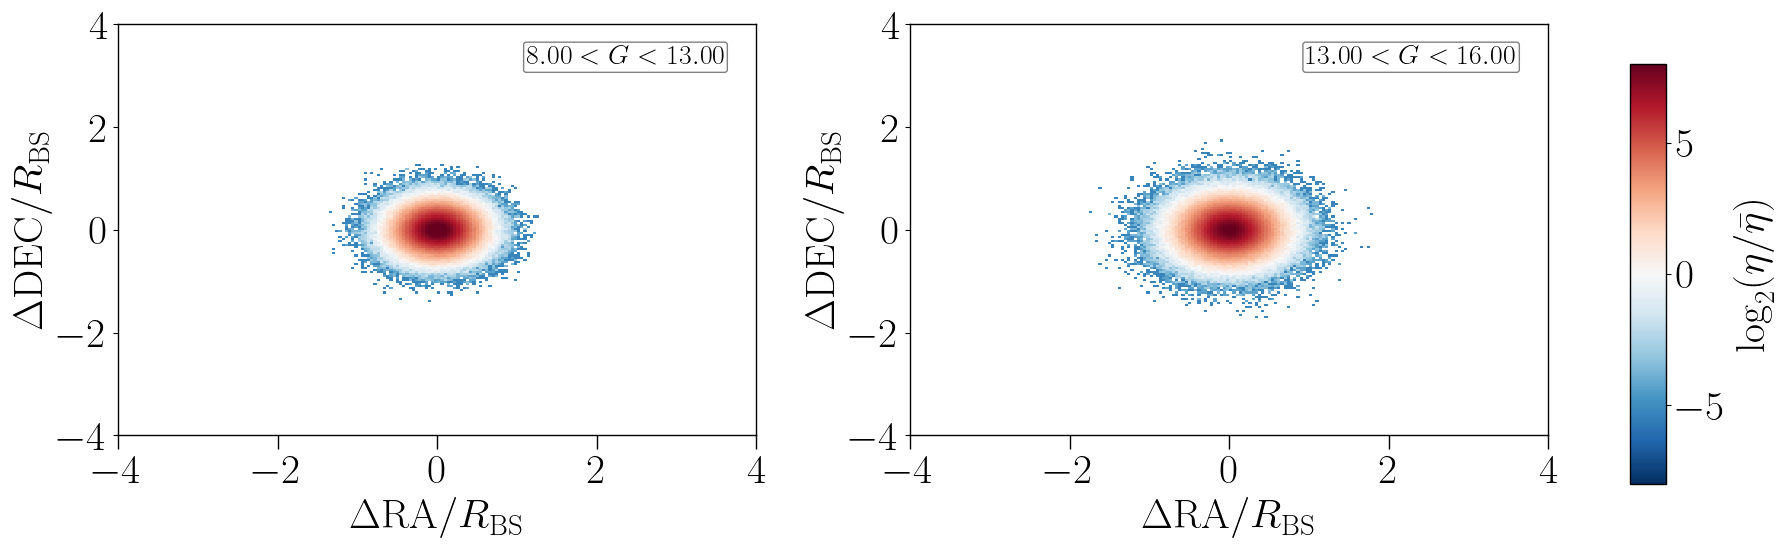

In [324]:


# --- your existing bins & setup ---
mag_bins = [(8, 13), (13, 16)]
nbins    = 200
r_extent = 4.0
annulus  = (0.1, 4.0)
dr       = 0.06

# --- placeholder functions: replace with the real DR8/DR9 formulas ---
def mask_radius_DR9(g):
    # DR9 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. piecewise interpolation from Legacy Surveys DR9 prescription.
    # Here’s a toy example:
    return 0.5*1630. * 1.396**(-g)

def mask_radius_DR8(g):
    # DR8 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. a different piecewise curve published for DR8.
    # Here’s a toy example that’s ~1.7× larger than DR9:
    return 2 * mask_radius_DR9(g)

# --- build BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'].values*u.deg,
                dec=bg['DEC'].values*u.deg)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=False, sharey=False)
for ax, (gmin, gmax) in zip(axes, mag_bins):
    # select stars in this bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values*u.deg,
                      dec=bright['dec'].values*u.deg)

    # match & compute offsets
    idx, _, _     = cats.match_to_catalog_sky(stars)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st)*np.cos(dec_st)
    dDec = dec_bg - dec_st

    # compute DR9 mask‐radii and scale
    mags_at_idx = bright['phot_g_mean_mag'].values[idx]
    R9_arcsec   = mask_radius_DR9(mags_at_idx)
    x = dRAc * 3600.0 / R9_arcsec
    y = dDec * 3600.0 / R9_arcsec

    # compute the DR8/DR9 ratio for your red circle
    R8_arcsec = mask_radius_DR8(mags_at_idx)
    red_radius = np.median(R8_arcsec / R9_arcsec)

    # 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    Rnorm    = np.sqrt(*np.meshgrid(Xc, Yc))
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-8, vmax=+8)
    ax.text (0.95, 0.95, fr"${gmin:4.2f}<G<{gmax:4.2f}$",
             transform=ax.transAxes, fontsize=20, verticalalignment='top',
             horizontalalignment='right', bbox=dict(facecolor='white', alpha=1, edgecolor='gray', boxstyle='round,pad=0.1'))
    
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # # black DR9 circle at unity
    # ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))
    # # red DR8 circle at the computed ratio
    # ax.add_patch(Circle((0,0), red_radius, fill=False, lw=2, ec='r'))

    # inset radial profile…
    rad    = np.sqrt(x**2 + y**2)
    r_bins = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r    = counts/areas
    log_eta  = np.log2(eta_r/eta_bar)



# final colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


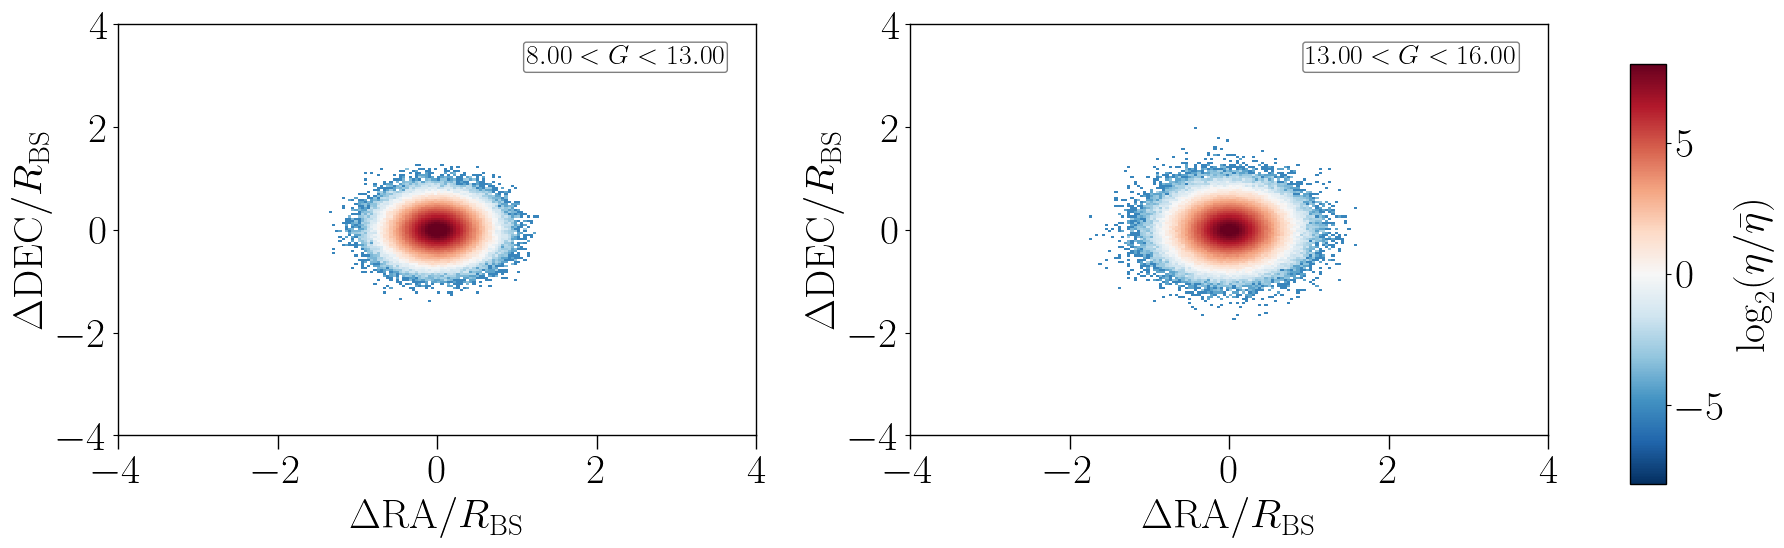

In [326]:


# --- your existing bins & setup ---
mag_bins = [(8, 13), (13, 16)]
nbins    = 200
r_extent = 4.0
annulus  = (0.1, 4.0)
dr       = 0.06

# --- placeholder functions: replace with the real DR8/DR9 formulas ---
def mask_radius_DR9(g):
    # DR9 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. piecewise interpolation from Legacy Surveys DR9 prescription.
    # Here’s a toy example:
    return 0.5*1630. * 1.396**(-g)

def mask_radius_DR8(g):
    # DR8 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. a different piecewise curve published for DR8.
    # Here’s a toy example that’s ~1.7× larger than DR9:
    return 2 * mask_radius_DR9(g)

# --- build BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'].values*u.deg,
                dec=bg['DEC'].values*u.deg)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=False, sharey=False)
for ax, (gmin, gmax) in zip(axes, mag_bins):
    # select stars in this bin
    sel    = (df_mask['G'] >= gmin) & (df_mask['G'] < gmax)
    bright = df_mask[sel]
    stars  = SkyCoord(ra=bright['RA_star'].values*u.deg,
                      dec=bright['DEC_star'].values*u.deg)

    # match & compute offsets
    idx, _, _     = cats.match_to_catalog_sky(stars)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st)*np.cos(dec_st)
    dDec = dec_bg - dec_st

    # compute DR9 mask‐radii and scale
    mags_at_idx = bright['G'].values[idx]
    R9_arcsec   = mask_radius_DR9(mags_at_idx)
    x = dRAc * 3600.0 / R9_arcsec
    y = dDec * 3600.0 / R9_arcsec

    # compute the DR8/DR9 ratio for your red circle
    R8_arcsec = mask_radius_DR8(mags_at_idx)
    red_radius = np.median(R8_arcsec / R9_arcsec)

    # 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    Rnorm    = np.sqrt(*np.meshgrid(Xc, Yc))
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-8, vmax=+8)
    ax.text (0.95, 0.95, fr"${gmin:4.2f}<G<{gmax:4.2f}$",
             transform=ax.transAxes, fontsize=20, verticalalignment='top',
             horizontalalignment='right', bbox=dict(facecolor='white', alpha=1, edgecolor='gray', boxstyle='round,pad=0.1'))
    
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

    # # black DR9 circle at unity
    # ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))
    # # red DR8 circle at the computed ratio
    # ax.add_patch(Circle((0,0), red_radius, fill=False, lw=2, ec='r'))

    # inset radial profile…
    rad    = np.sqrt(x**2 + y**2)
    r_bins = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r    = counts/areas
    log_eta  = np.log2(eta_r/eta_bar)



# final colourbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


In [ ]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- your existing bins & setup ---
mag_bins = [(8, 11), (11, 12), (12, 13), (13, 14), (14, 15), (15, 16)]
nbins    = 200
r_extent = 4.0
annulus  = (1.1, 4.0)
dr       = 0.06

# --- placeholder functions: replace with the real DR8/DR9 formulas ---
def mask_radius_DR9(g):
    # DR9 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. piecewise interpolation from Legacy Surveys DR9 prescription.
    # Here’s a toy example:
    return  10**(0.2*(13 - g))

def mask_radius_DR8(g):
    # DR8 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. a different piecewise curve published for DR8.
    # Here’s a toy example that’s ~1.7× larger than DR9:
    return 2 * mask_radius_DR9(g)

# --- build BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'].values*u.deg,
                dec=bg['DEC'].values*u.deg)


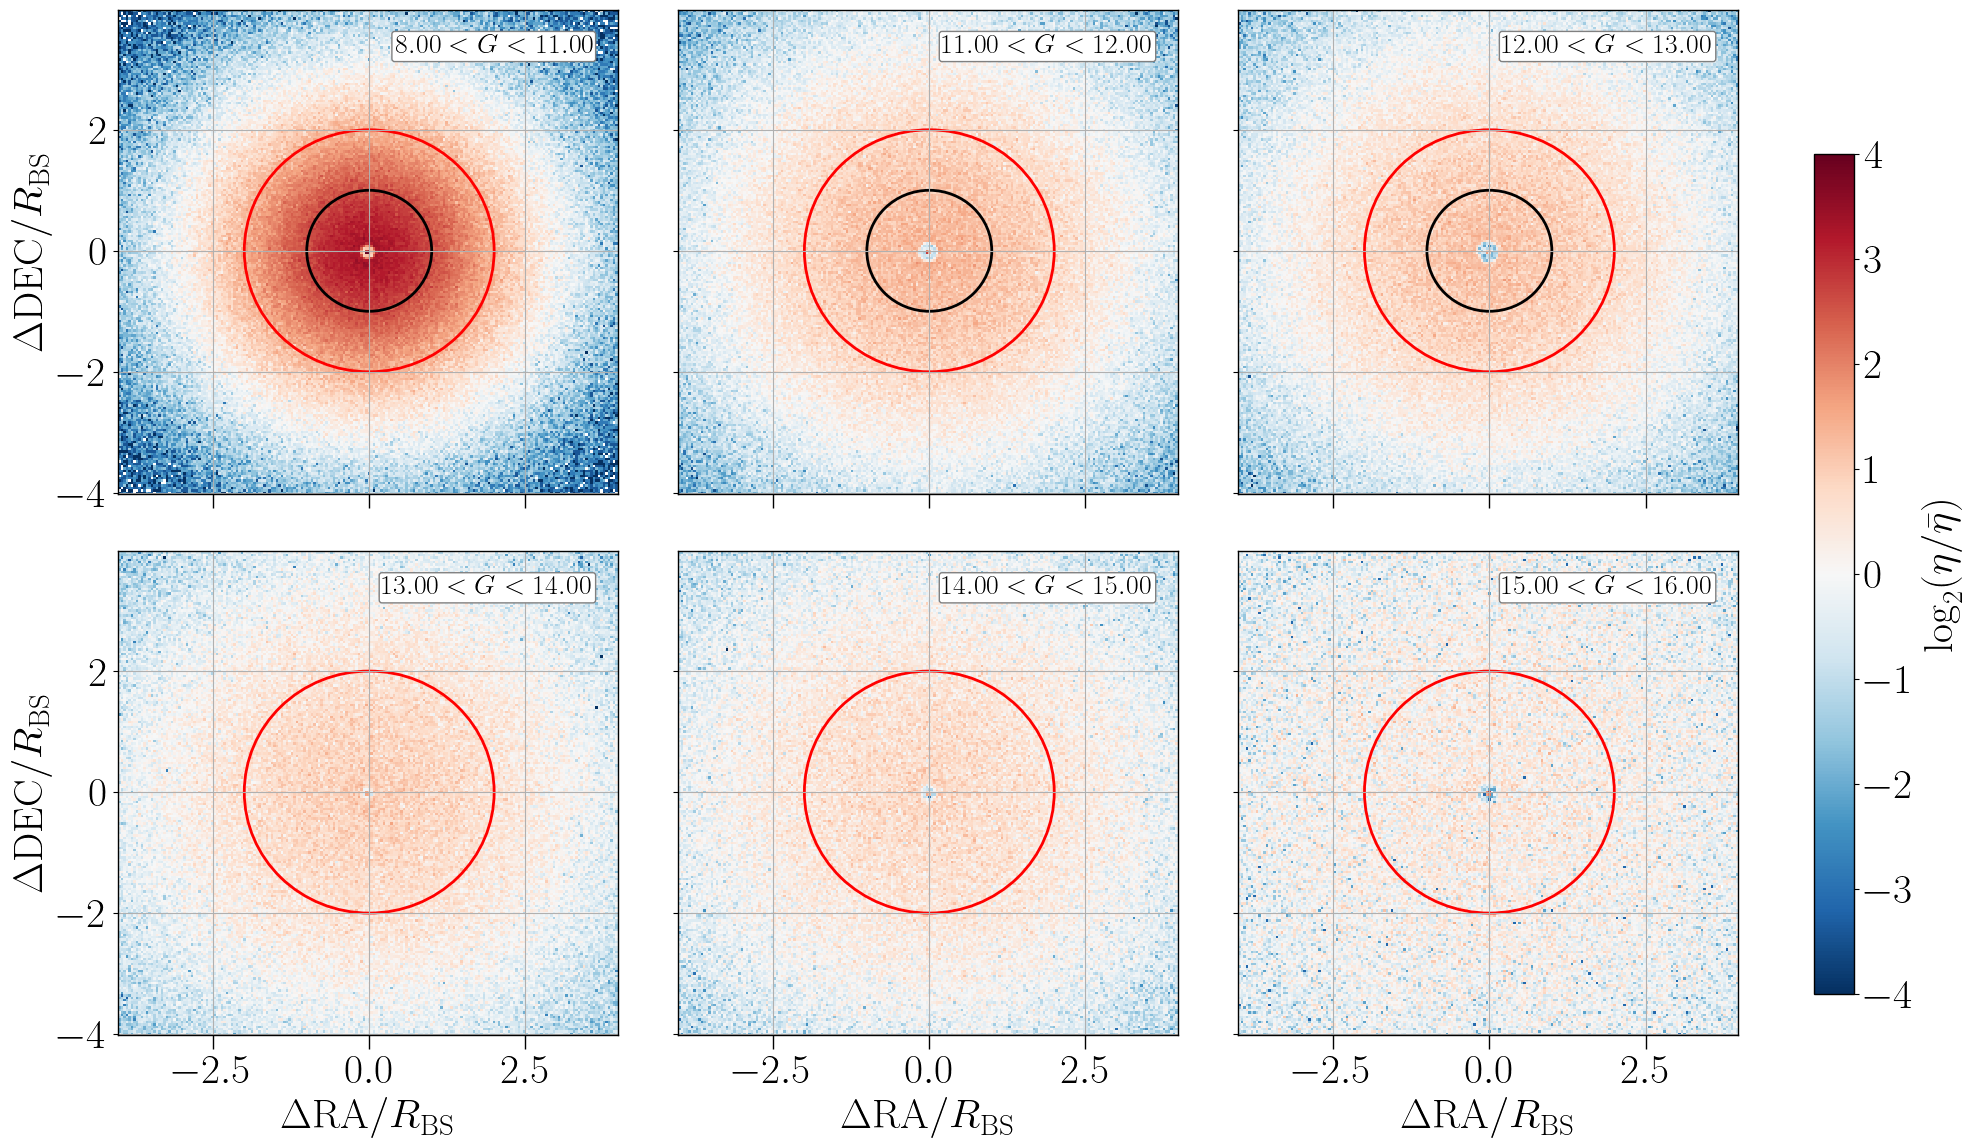

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharex=True, sharey=True)

axes = axes.flatten()
fig.subplots_adjust(hspace=0.001, wspace=0.001)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # select stars in this bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values*u.deg,
                      dec=bright['dec'].values*u.deg)

    # match & compute offsets
    idx, _, _     = cats.match_to_catalog_sky(stars)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st)*np.cos(dec_st)
    dDec = dec_bg - dec_st

    # compute DR9 mask‐radii and scale
    mags_at_idx = bright['phot_g_mean_mag'].values[idx]
    R9_arcsec   = mask_radius_DR9(mags_at_idx)
    x = dRAc * 3600.0 / R9_arcsec
    y = dDec * 3600.0 / R9_arcsec

    # compute the DR8/DR9 ratio for your red circle
    R8_arcsec = mask_radius_DR8(mags_at_idx)
    red_radius = np.median(R8_arcsec / R9_arcsec)

    # 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    Rnorm    = np.sqrt(*np.meshgrid(Xc, Yc))
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    pcm = ax.pcolormesh(xe[:-1], ye[:-1], np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    # ax.set_title(f'{gmin} ≤ G < {gmax}')

    # black DR9 circle at unity
    if gmax <= 13:
        ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))
    # red DR8 circle at the computed ratio
    ax.add_patch(Circle((0,0), red_radius, fill=False, lw=2, ec='r'))
    ax.text (0.95, 0.95, fr"${gmin:4.2f}<G<{gmax:4.2f}$",
             transform=ax.transAxes, fontsize=20, verticalalignment='top',
             horizontalalignment='right', bbox=dict(facecolor='white', alpha=1, edgecolor='gray', boxstyle='round,pad=0.1'))
    
    # inset radial profile…
    rad    = np.sqrt(x**2 + y**2)
    r_bins = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r    = counts/areas
    log_eta  = np.log2(eta_r/eta_bar)
    ax.grid()
    # axins = inset_axes(ax, width="40%", height="30%", loc='upper right', borderpad=1)
    # axins.plot(r_c, log_eta, color='r', lw=1)
    # axins.axhline(0, color='k', lw=0.8)
    # axins.set_xlim(0, r_extent)
    # axins.set_ylim(-4, 4)
    # axins.set_xlabel('$r/R_{\\rm BS}$', fontsize=7)
    # axins.set_ylabel('$\log_2(\\eta/\\bar\\eta)$', fontsize=7)
    # axins.tick_params(labelsize=6)

# final colourbar
axes[0].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[3].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[3].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[4].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


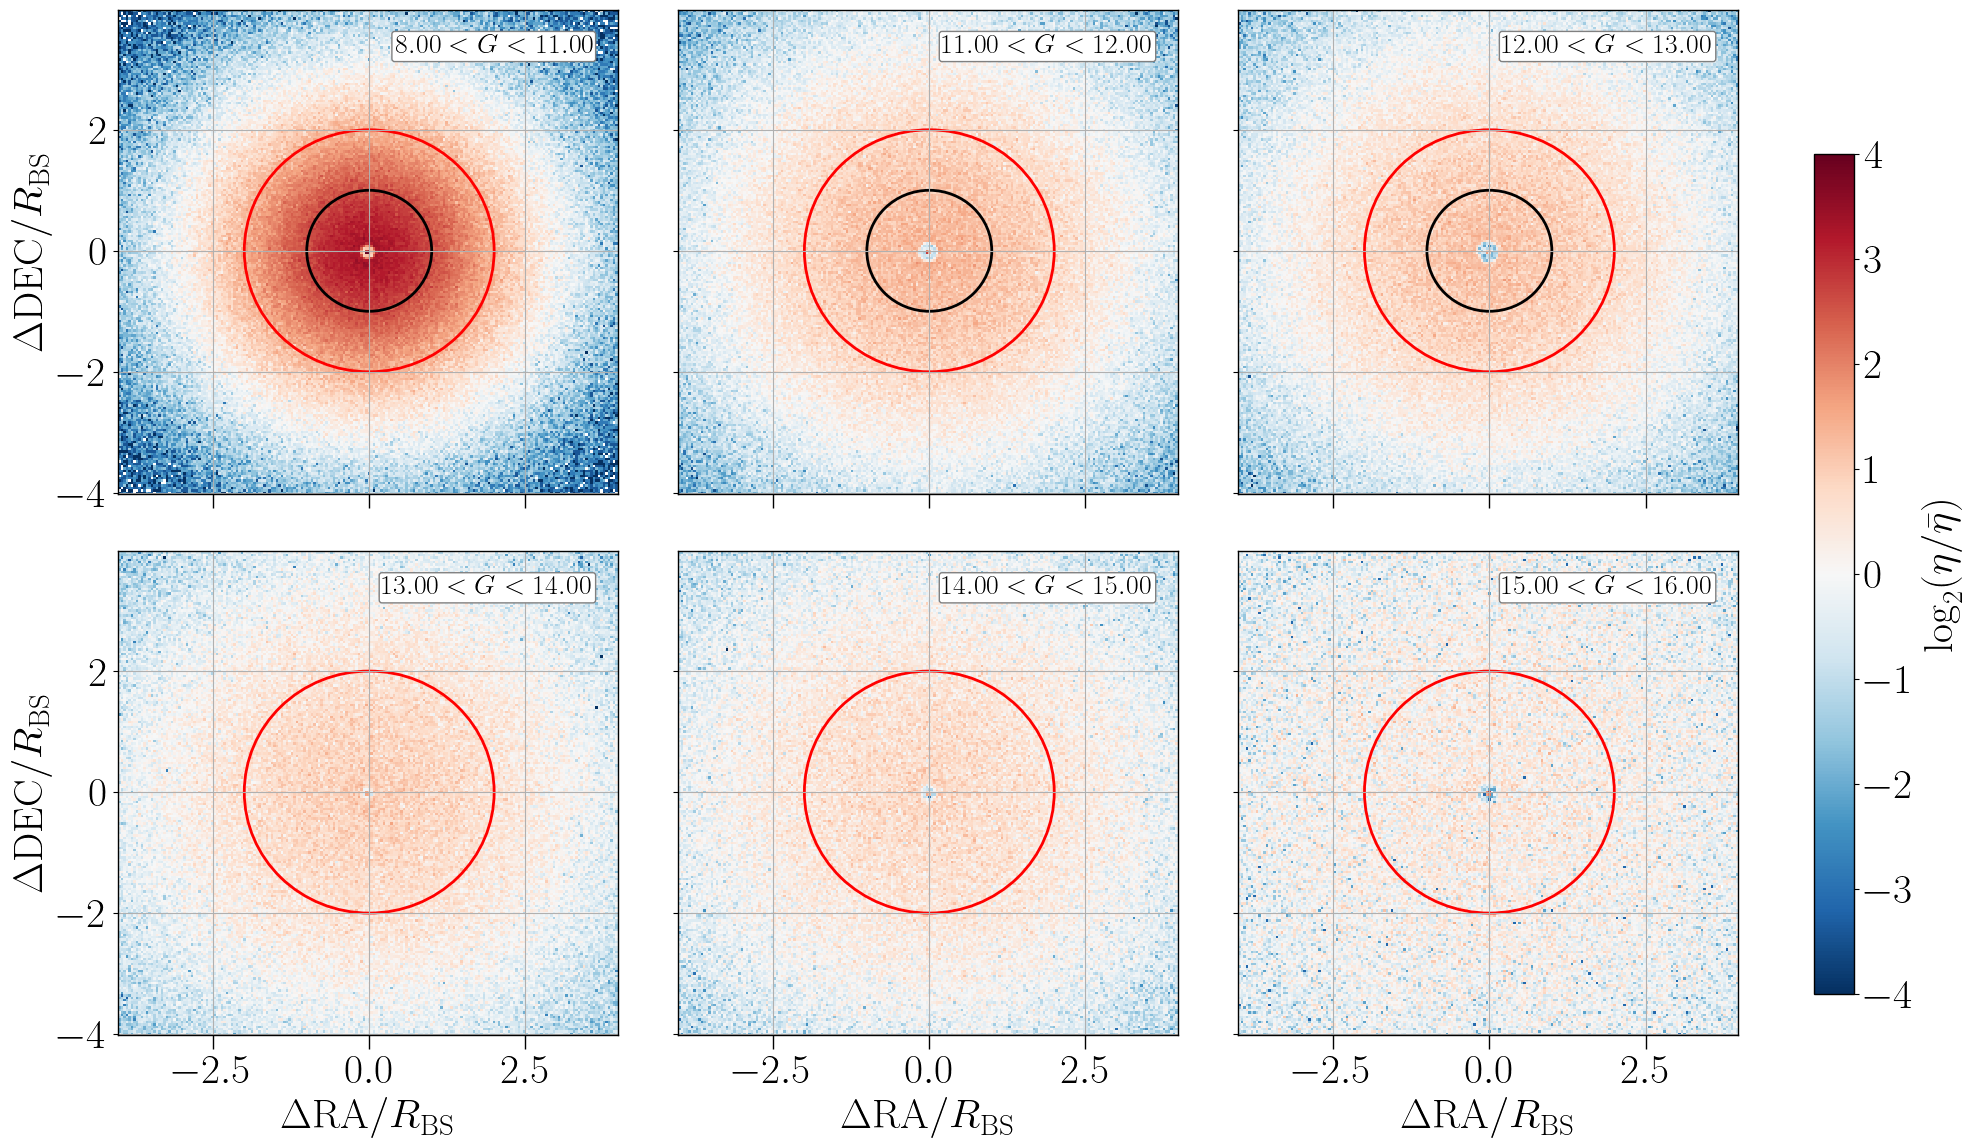

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharex=True, sharey=True)

axes = axes.flatten()
fig.subplots_adjust(hspace=0.001, wspace=0.001)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # select stars in this bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values*u.deg,
                      dec=bright['dec'].values*u.deg)

    # match & compute offsets
    idx, _, _     = cats.match_to_catalog_sky(stars)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st)*np.cos(dec_st)
    dDec = dec_bg - dec_st

    # compute DR9 mask‐radii and scale
    mags_at_idx = bright['phot_g_mean_mag'].values[idx]
    R9_arcsec   = mask_radius_DR9(mags_at_idx)
    x = dRAc * 3600.0 / R9_arcsec
    y = dDec * 3600.0 / R9_arcsec

    # compute the DR8/DR9 ratio for your red circle
    R8_arcsec = mask_radius_DR8(mags_at_idx)
    red_radius = np.median(R8_arcsec / R9_arcsec)

    # 2D histogram & normalised density
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    Rnorm    = np.sqrt(*np.meshgrid(Xc, Yc))
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    pcm = ax.pcolormesh(xe[:-1], ye[:-1], np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4)
    # ax.set_title(f'{gmin} ≤ G < {gmax}')

    # black DR9 circle at unity
    if gmax <= 13:
        ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))
    # red DR8 circle at the computed ratio
    ax.add_patch(Circle((0,0), red_radius, fill=False, lw=2, ec='r'))
    ax.text (0.95, 0.95, fr"${gmin:4.2f}<G<{gmax:4.2f}$",
             transform=ax.transAxes, fontsize=20, verticalalignment='top',
             horizontalalignment='right', bbox=dict(facecolor='white', alpha=1, edgecolor='gray', boxstyle='round,pad=0.1'))
    
    # inset radial profile…
    rad    = np.sqrt(x**2 + y**2)
    r_bins = np.arange(0, r_extent+dr, dr)
    r_c    = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    eta_r    = counts/areas
    log_eta  = np.log2(eta_r/eta_bar)
    ax.grid()
    # axins = inset_axes(ax, width="40%", height="30%", loc='upper right', borderpad=1)
    # axins.plot(r_c, log_eta, color='r', lw=1)
    # axins.axhline(0, color='k', lw=0.8)
    # axins.set_xlim(0, r_extent)
    # axins.set_ylim(-4, 4)
    # axins.set_xlabel('$r/R_{\\rm BS}$', fontsize=7)
    # axins.set_ylabel('$\log_2(\\eta/\\bar\\eta)$', fontsize=7)
    # axins.tick_params(labelsize=6)

# final colourbar
axes[0].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[3].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[3].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[4].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
plt.tight_layout(rect=[0,0,0.9,1])
plt.show()


In [196]:
df_mask = Table.read('/its/home/bb345/5-4most_data/other_data/gaia_sources/gaia-mask-dr10_crs_foot.fits')
df_mask = df_mask.to_pandas()

In [198]:

# 1. Make SkyCoord objects
stars = SkyCoord(ra=df_mask['RA_star'].values*u.deg,
                 dec=df_mask['DEC_star'].values*u.deg)
cats  = SkyCoord(ra=bg['RA'].values*u.deg,
                 dec=bg['DEC'].values*u.deg)

# 2. Turn to 3D unit vectors for KDTree
def sph_to_cart(scoord):
    ra, dec = scoord.ra.rad, scoord.dec.rad
    return np.vstack((np.cos(dec)*np.cos(ra),
                      np.cos(dec)*np.sin(ra),
                      np.sin(dec))).T

star_xyz = sph_to_cart(stars)
cat_xyz  = sph_to_cart(cats)
tree     = cKDTree(star_xyz)

# 3. Find nearest neighbour
dist3d, idx = tree.query(cat_xyz, k=1)

# 4. Compute true on-sky separation
sep = cats.separation(stars[idx])             # astropy Angle, in deg

# 5. Pick the mask radius column you want:
#    e.g. in arcsec → convert to deg
R_BS_arcsec = df_mask['R_bright_arcsec'].values[idx]
R_BS_deg    = (R_BS_arcsec * u.arcsec).to(u.deg).value

# 6. Scaled radius
r_scaled = sep.deg / R_BS_deg


In [200]:
star_ra  = df_mask['RA_star'].values[idx]
star_dec = df_mask['DEC_star'].values[idx]

# Raw offsets in degrees
dRA_deg  = (bg['RA'].values - star_ra) * np.cos(np.radians(star_dec))
dDec_deg = bg['DEC'].values - star_dec

# Normalise by mask radius
dRA_scaled  = dRA_deg  / R_BS_deg
dDec_scaled = dDec_deg / R_BS_deg


In [201]:
# 1. Define bins
nbins = 200
edges = np.linspace(-4, 4, nbins+1)

# 2. 2D histogram of raw counts
H, xedges, yedges = np.histogram2d(
    dRA_scaled, dDec_scaled,
    bins=[edges, edges]
)

# 3. Compute pixel centres
xc = 0.5*(xedges[:-1] + xedges[1:])
yc = 0.5*(yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xc, yc, indexing='xy')
Rgrid = np.hypot(X, Y)

# 4. Mean density in 1<r<4
mask_annulus = (Rgrid > 1) & (Rgrid < 4)
mean_density = H[mask_annulus].mean()

# 5. Log₂ ratio
with np.errstate(divide='ignore', invalid='ignore'):
    log2_eta = np.log2(H / mean_density)
    log2_eta[~np.isfinite(log2_eta)] = np.nan  # mask zeros


In [213]:
stars = df_mask[df_mask['ismedium']]


In [217]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# pick only the bright stars
stars = df_mask[df_mask['ismedium']]

# histogram setup
lim    = 1000               # ±1000 arcsec
nbins  = 200
edges  = np.linspace(-lim, lim, nbins+1)
Htot   = np.zeros((nbins, nbins))

for _, star in stars.iterrows():
    ra0  = star['RA_star']
    dec0 = star['DEC_star']

    # convert dec0 to radians before taking cosine!
    cosdec = np.cos(np.deg2rad(dec0))

    # compute offsets in arcsec
    dra  = ( bg['RA']  - ra0  ) * cosdec * 3600.0
    ddec = ( bg['DEC'] - dec0 ) * 3600.0

    # optional speed-up: discard points outside your ±lim box
    mask = (np.abs(dra) <= lim) & (np.abs(ddec) <= lim)
    dra, ddec = dra[mask], ddec[mask]

    # accumulate
    H, _, _ = np.histogram2d(dra, ddec, bins=[edges, edges])
    Htot += H




KeyboardInterrupt: 

In [ ]:
# normalise per star and per arcsec²
bin_area = (edges[1] - edges[0])**2
Hnorm    = Htot / len(stars) / bin_area

# plot
fig, ax = plt.subplots(figsize=(6,6))
im = ax.imshow(Hnorm.T,
               origin='lower',
               extent=[-lim, lim, -lim, lim],
               norm=LogNorm(vmin=0.3, vmax=3),
               cmap='viridis')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('〈ρ〉/ρ̄')

# overplot mean mask radius
rmean = stars['R_bright_arcsec'].mean()
circ  = plt.Circle((0,0), rmean, edgecolor='black', fill=False)
ax.add_patch(circ)

ax.set_xlabel('ΔRA (arcsec)')
ax.set_ylabel('ΔDec (arcsec)')
plt.show()

In [224]:
# --- placeholder functions: replace with the real DR8/DR9 formulas ---
def mask_radius_DR9(g):
    # DR9 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. piecewise interpolation from Legacy Surveys DR9 prescription.
    # Here’s a toy example:
    return  10**(0.2*(13 - g))

def mask_radius_DR8(g):
    # DR8 bright‐star mask radius [arcsec] as a function of G-mag
    # e.g. a different piecewise curve published for DR8.
    # Here’s a toy example that’s ~1.7× larger than DR9:
    return 2 * mask_radius_DR9(g)
    
def mask_radius_for_mag(mag):
    # Returns a masking radius in degrees for a star of the given magnitude.
    # Used for Tycho-2 and Gaia stars.

    # This is in degrees, and is from Rongpu in the thread [decam-chatter 12099].
    return 1630./3600. * 1.396**(-mag)
# --- build BG SkyCoord once ---
cats = SkyCoord(ra=bg['RA'].values*u.deg,
                dec=bg['DEC'].values*u.deg)

In [273]:
mag_bins = [(8, 11), (11, 12), (12, 13), (13, 14), (14, 15), (15, 16)]
nbins    = 100
r_extent = 1000      # we'll plot −4 to +4 in units of R_BS
annulus   = (1.1, 4)

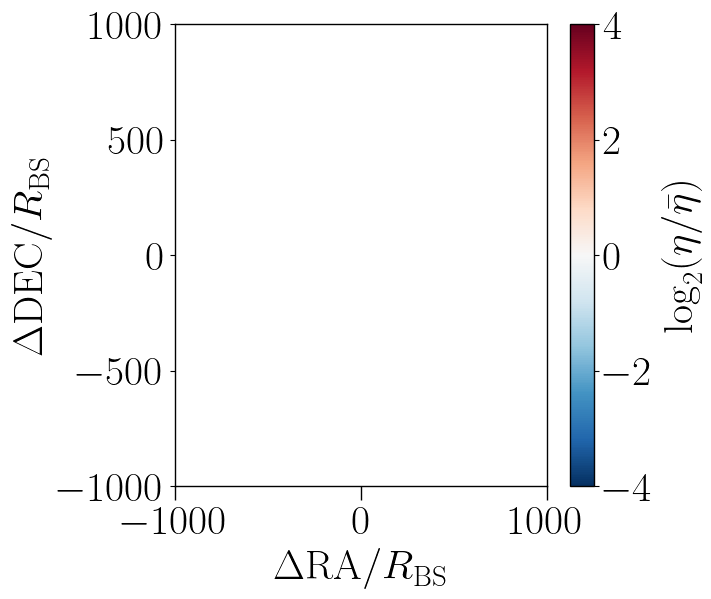

In [275]:

# 2. Select “bright” stars (e.g. G ≤ 13) and turn into SkyCoords
bright = gaia[gaia['phot_g_mean_mag'] <= 16]
stars = SkyCoord(ra=bright['ra'].values * u.deg,
                 dec=bright['dec'].values * u.deg)

# 3. Make a SkyCoord for your BG objects
cats  = SkyCoord(ra=bg['RA'].values * u.deg,
                 dec=bg['DEC'].values * u.deg)

# 4. Cross-match each BG to its nearest bright star
idx, sep2d, _ = cats.match_to_catalog_sky(stars)

# 5. Compute ΔRA, ΔDec (in the tangent-plane sense)
#    – we want small-angle approx: ΔRA_c = (RA_BG − RA_star)⋅cos(Dec_star)
ra_bg  = cats.ra.rad
dec_bg = cats.dec.rad
ra_st  = stars[idx].ra.rad
dec_st = stars[idx].dec.rad

dRA_c  = (ra_bg  - ra_st ) * np.cos(dec_st)
dDec   =  dec_bg - dec_st

# 6. Define the bright-star masking radius R_BS(m)
#    – Zarrouk et al. use a lookup or fit: e.g. RBS = f(mag)
#      here’s a toy linear example; you’ll need the real curve:
R_BS = 10**(0.2 * (13 - bright['phot_g_mean_mag'].values[idx]))  # in arcsec, say
R_BS = 1630. * 1.396**(-bright['phot_g_mean_mag'].values[idx])
# 7. Scale your separations by that radius
x = dRA_c  * 3600. / R_BS   # now dimensionless ΔRA/RBS
y = dDec   * 3600. / R_BS   # dimensionless ΔDec/RBS

# 8. Make a 2D histogram of (x,y)
nbins = 200
H, xe, ye = np.histogram2d(x, y, bins=nbins, range=[[-4,4],[-4,4]])
#  how to turn that into a density *ratio* η/η̄ ?
#  – compute the mean density in an annulus 1.1<R<4:
Xc, Yc = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
XX, YY = np.meshgrid(Xc,Yc)
R = np.sqrt(XX**2 + YY**2)
mask = (R>1.1) & (R<4)
eta_mean = H[mask].mean()
density_ratio = H / eta_mean

# 9. Plot
fig, ax = plt.subplots(figsize=(6,6))
pcm = ax.pcolormesh(xe, ye, np.log2(density_ratio).T,
                    cmap='RdBu_r', vmin=-4, vmax=+4)
fig.colorbar(pcm, label=r'$\log_2(\eta/\bar\eta)$')

# 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
# for rad, col in [(1,'k'), (2,'r')]:
    # circ = Circle((0,0), radius=rad, fill=False, ls='-', lw=2, ec=col)
    # ax.add_patch(circ)

ax.set_xlim(-1000,1000)
ax.set_ylim(-1000,1000)
# ax.axhline(0, color='k', lw=1)
# ax.axvline(0, color='k', lw=1)
ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

# 11. Compute & overplot the radial density profile
r_bins = np.linspace(0,4,80)
r_cent = 0.5*(r_bins[:-1]+r_bins[1:])
# compute annular counts
rad = np.sqrt(x**2 + y**2)
counts, _ = np.histogram(rad, bins=r_bins)
area = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
eta_r = counts / area
# normalise & log2
eta_r_norm = eta_r / eta_mean


plt.show()


In [272]:
# … inside your loop, after matching and computing dRAc, dDec …

# compute mask radius
mags_idx     = bright['phot_g_mean_mag'].values[idx]
R_deg        = mask_radius_for_mag(mags_idx)      # in degrees
R_BS_arcsec  = R_deg * 3600.0                     # in arcsec

# debug
print(f"G in [{gmin},{gmax}): R_deg [deg] = {R_deg[:5]}…{R_deg[-5:]}")
print(f" → R_BS_arcsec [\"] min/med/max = "
      f"{R_BS_arcsec.min():.1f}/{np.median(R_BS_arcsec):.1f}/{R_BS_arcsec.max():.1f}")

# normalise
x = dRAc * 3600.0 / R_BS_arcsec
y = dDec        * 3600.0 / R_BS_arcsec
print(f" → x spans {x.min():.2e} … {x.max():.2e}")

# now build the histogram in [–4,4] as before …


G in [15,16): R_deg [deg] = [0.00311515 0.00495288 0.00291496 0.00748411 0.0050493 ]…[0.00490403 0.00320097 0.00266568 0.00266568 0.00255956]
 → R_BS_arcsec ["] min/med/max = 7.8/13.3/732.7
 → x spans -2.38e+03 … 2.34e+03


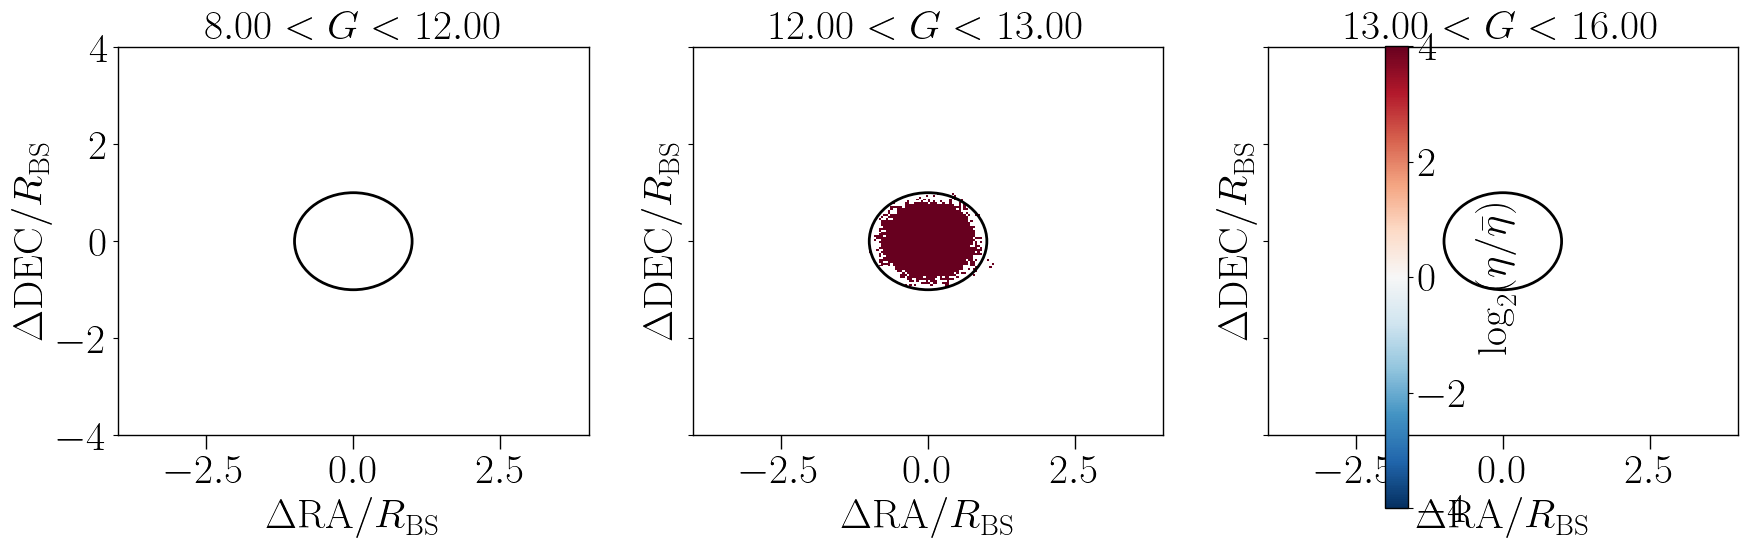

In [277]:

# your real mask-radius function (returns degrees)
def mask_radius_for_mag(mag):
    # thread [decam-chatter 12099]:
    return 1630./3600. * 1.396**(-mag)

# ---- parameters ----
mag_bins = [(8,12), (12,13), (13,16)]
nbins    = 200
r_extent = 4.0
annulus  = (1.1, 4.0)
dr       = 0.06

# turn BG into SkyCoord once
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

# prepare figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # 1) select Gaia stars in this G-mag bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values * u.deg,
                      dec=bright['dec'].values * u.deg)

    # 2) match BG → bright stars
    idx, _, _ = cats.match_to_catalog_sky(stars)

    # 3) compute tangent-plane offsets (radians)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st) * np.cos(dec_st)
    dDec =  dec_bg - dec_st

    # 4) compute mask radius per star in arcsec
    mags_idx    = bright['phot_g_mean_mag'].values[idx]
    R_deg       = mask_radius_for_mag(mags_idx)  # in degrees
    R_arcsec    = R_deg * 3600.0                 # convert to arcsec

    # 5) normalise offsets ΔRA and ΔDec by R_BS
    x = (dRAc * 3600.0) / R_arcsec
    y = (dDec      * 3600.0) / R_arcsec

    # 6) build 2D histogram & density ratio η/η̄
    H, xe, ye = np.histogram2d(x, y,
                               bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc    = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    XX, YY    = np.meshgrid(Xc, Yc)
    Rnorm     = np.sqrt(XX**2 + YY**2)
    annmask   = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar   = H[annmask].mean()
    densrat   = H / eta_bar

    # 7) plot the 2D log₂ density map
    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=4)
    ax.set_xlim(-r_extent, r_extent)
    ax.set_ylim(-r_extent, r_extent)

    # 8) overplot the DR9 mask circle (R=1)
    ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))

    # 9) compute & overplot the radial profile (width dr)
    rad      = np.sqrt(x**2 + y**2)
    r_bins   = np.arange(0, r_extent+dr, dr)
    r_cent   = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    log_eta  = np.log2((counts/areas) / eta_bar)

    # overlay on the same axes
    ax.plot(r_cent,    log_eta, color='r', lw=2)  # horizontal
    ax.plot(log_eta,   r_cent,  color='r', lw=2)  # vertical

    # labels
    ax.set_title(fr"${gmin:4.2f}<G<{gmax:4.2f}$")
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

# 10) single colourbar for all panels
cbar = fig.colorbar(pcm, ax=axes.ravel().tolist(),
                    label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout()
plt.show()


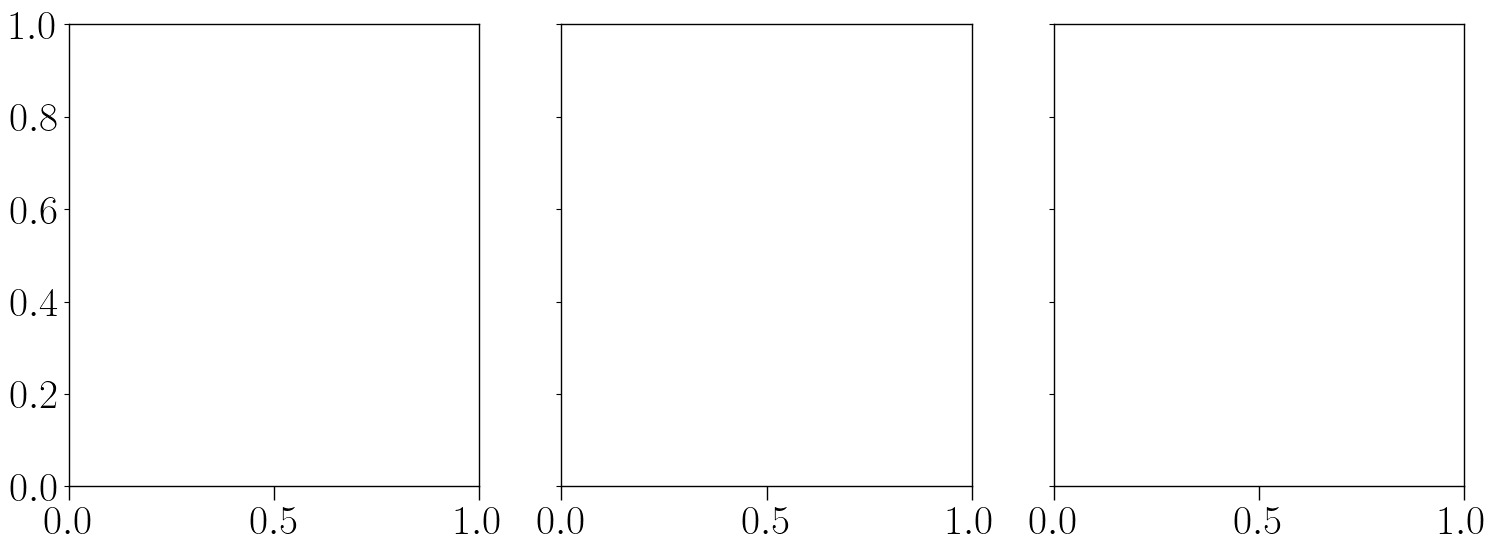

In [278]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
from matplotlib.patches import Circle

# ----------------------------------------------------------------
# Your mask-radius function (returns degrees)
def mask_radius_for_mag(mag):
    # From decam-chatter thread 12099:
    return 1630. / 3600. * 1.396**(-mag)
# ----------------------------------------------------------------

# 1×3 panels for these G-mag bins
mag_bins = [(8, 12), (12, 13), (13, 16)]

# Pre-make the BG catalogue SkyCoord
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

# Set up the figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Loop over bins
for ax, (gmin, gmax) in zip(axes, mag_bins):
    # --- Select bright Gaia stars in this bin ---
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values * u.deg,
                      dec=bright['dec'].values * u.deg)

    # --- Cross-match BG objects to nearest bright star ---
    idx, _, _ = cats.match_to_catalog_sky(stars)

    # --- Compute small-angle offsets in radians ---
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st) * np.cos(dec_st)
    dDec = dec_bg - dec_st

    # --- Compute the masking radius R_BS in arcsec ---
    mags_idx    = bright['phot_g_mean_mag'].values[idx]
    R_deg       = mask_radius_for_mag(mags_idx)      # in degrees
    R_BS        = R_deg * 3600.0                     # convert to arcsec

    # --- Normalise offsets by R_BS ---
    x = (dRAc * 3600.0) / R_BS   # ΔRA/R_BS


Bin 8–12: 234542 Gaia stars
  Matched 1537684 BG objects
  R_arcsec: min=29.8, med=39.0, max=113.0
  x span: -685.55 to 635.81
  Kept 1537085 points inside ±4.0
Bin 12–13: 276966 Gaia stars
  Matched 1537684 BG objects
  R_arcsec: min=21.3, med=24.5, max=29.8
  x span: -941.39 to 930.63
  Kept 1537032 points inside ±4.0
Bin 13–16: 2374812 Gaia stars
  Matched 1537684 BG objects
  R_arcsec: min=7.8, med=12.1, max=21.3
  x span: -2384.72 to 2344.68
  Kept 1537410 points inside ±4.0


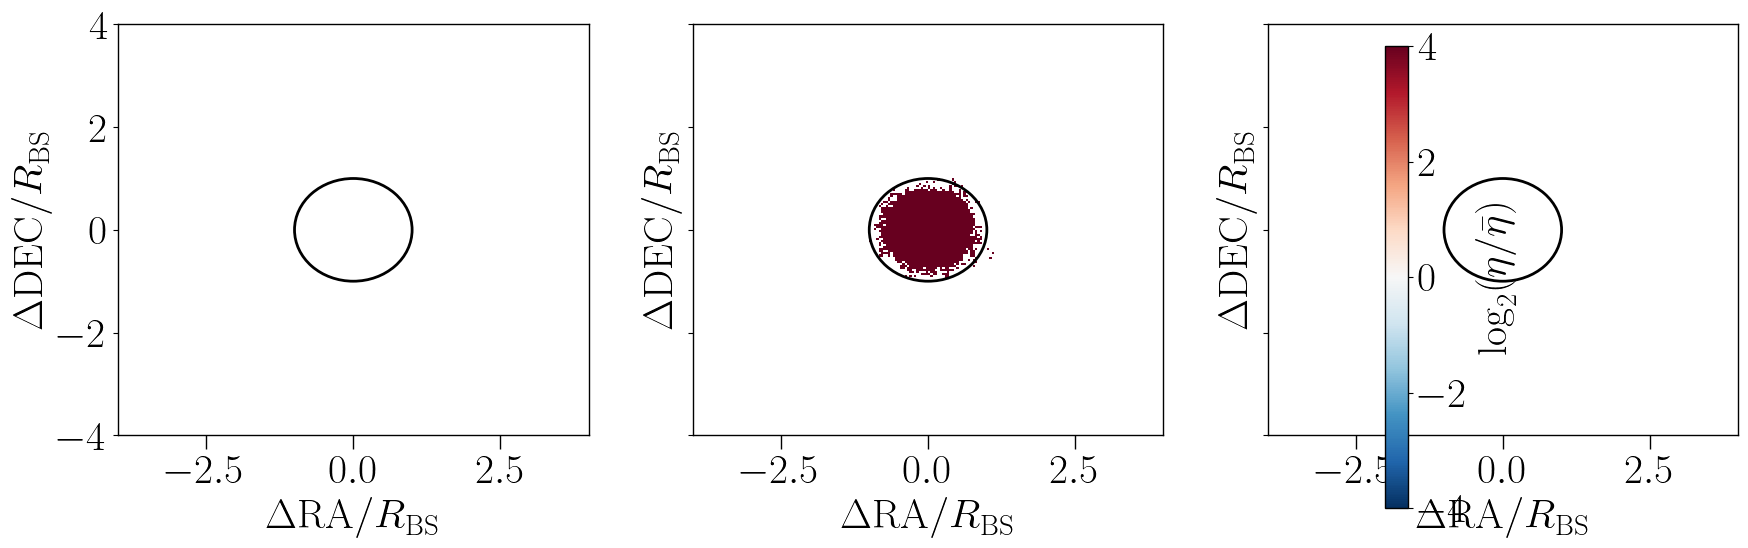

In [280]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
from matplotlib.patches import Circle

# --- Your mask‐radius function (returns degrees) ---
def mask_radius_for_mag(mag):
    return 1630./3600. * 1.396**(-mag)

# --- Configuration ---
mag_bins = [(8,12), (12,13), (13,16)]
nbins    = 200
r_extent = 4.0
annulus  = (1.1, 4.0)
dr       = 0.06

# --- Build SkyCoord for your BG catalogue once ---
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

# --- Set up figure ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # 1) Select Gaia stars in this magnitude range
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    print(f"Bin {gmin}–{gmax}: {len(bright)} Gaia stars")  # debug

    # 2) Make SkyCoord and cross-match
    stars = SkyCoord(ra=bright['ra'].values * u.deg,
                     dec=bright['dec'].values * u.deg)
    idx, sep2d, _ = cats.match_to_catalog_sky(stars)
    print(f"  Matched {len(idx)} BG objects")            # debug

    # 3) Compute tangent-plane offsets (radians)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st) * np.cos(dec_st)
    dDec = dec_bg - dec_st

    # 4) Compute masking radius (deg → arcsec)
    mags_idx   = bright['phot_g_mean_mag'].values[idx]
    R_deg      = mask_radius_for_mag(mags_idx)  # in degrees
    R_arcsec   = R_deg * 3600.0                 # in arcsec
    print(f"  R_arcsec: min={R_arcsec.min():.1f}, med={np.median(R_arcsec):.1f}, max={R_arcsec.max():.1f}")  # debug

    # 5) Normalise offsets into units of R_BS
    x = (dRAc * 3600.0) / R_arcsec
    y = (dDec      * 3600.0) / R_arcsec
    print(f"  x span: {x.min():.2f} to {x.max():.2f}")  # debug

    # 6) Clip to the [–4,4] window
    keep = (np.abs(x) <= r_extent) & (np.abs(y) <= r_extent)
    x2, y2 = x[keep], y[keep]
    print(f"  Kept {len(x2)} points inside ±{r_extent}")  # debug

    # 7) 2D histogram + density ratio
    H, xe, ye = np.histogram2d(x2, y2, bins=nbins,
                               range=[[-r_extent, r_extent],
                                      [-r_extent, r_extent]])
    Xc, Yc   = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    XX, YY   = np.meshgrid(Xc, Yc)
    Rnorm    = np.sqrt(XX**2 + YY**2)
    annmask  = (Rnorm>annulus[0]) & (Rnorm<annulus[1])
    eta_bar  = H[annmask].mean()
    densrat  = H / eta_bar

    # 8) Plot the log₂ density‐ratio map
    pcm = ax.pcolormesh(xe, ye, np.log2(densrat).T,
                        cmap='RdBu_r', vmin=-4, vmax=+4,
                        shading='auto')
    ax.set_xlim(-r_extent, r_extent)
    ax.set_ylim(-r_extent, r_extent)

    # 9) Black circle at R=1
    ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))

    # 10) Compute & overplot radial profile
    rad      = np.sqrt(x2**2 + y2**2)
    r_bins   = np.arange(0, r_extent+dr, dr)
    r_cent   = 0.5*(r_bins[:-1] + r_bins[1:])
    counts,_ = np.histogram(rad, bins=r_bins)
    areas    = np.pi*(r_bins[1:]**2 - r_bins[:-1]**2)
    log_eta  = np.log2((counts/areas) / eta_bar)

    ax.plot(r_cent,  log_eta, color='r', lw=2)
    ax.plot(log_eta, r_cent,  color='r', lw=2)

    # Labels
    # ax.set_title(f'{gmin} ≤ G < {gmax}')
    ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

# 11) One shared colourbar
cbar = fig.colorbar(pcm, ax=axes.ravel().tolist(),
                    label=r'$\log_2(\eta/\bar\eta)$')

plt.tight_layout()
plt.show()


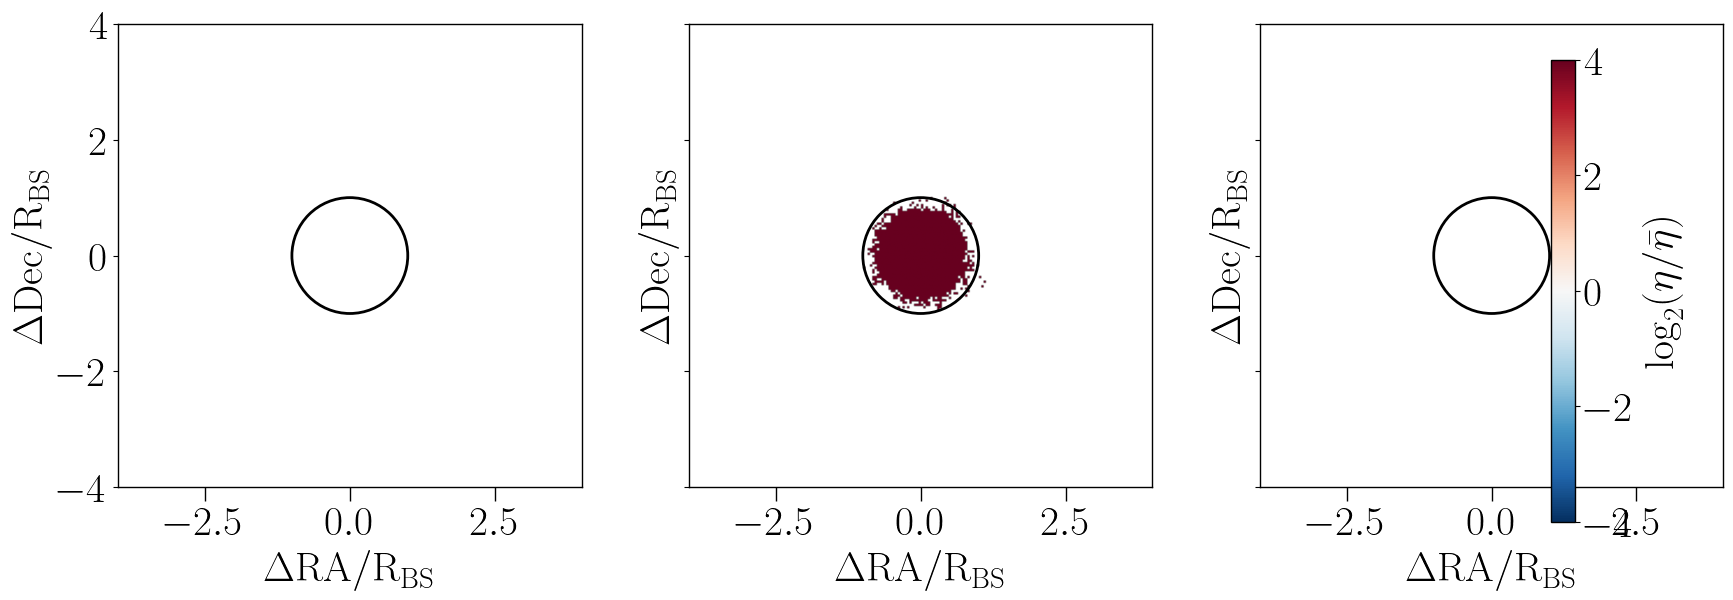

In [281]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
from matplotlib.patches import Circle

# Your mask‐radius function (returns degrees)
def mask_radius_for_mag(mag):
    return 1630./3600. * 1.396**(-mag)

# Bins and constants
mag_bins = [(8,12), (12,13), (13,16)]
r_ext    = 4.0   # plot limits ±4
dr       = 0.06

# Precompute BG coords
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (gmin, gmax) in zip(axes, mag_bins):
    # 1) pick Gaia stars
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values * u.deg,
                      dec=bright['dec'].values * u.deg)

    # 2) match
    idx, _, _ = cats.match_to_catalog_sky(stars)

    # 3) small‐angle offsets [rad]
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st) * np.cos(dec_st)
    dDec =  dec_bg - dec_st

    # 4) mask radius [arcsec]
    mags_idx = bright['phot_g_mean_mag'].values[idx]
    R_deg    = mask_radius_for_mag(mags_idx)
    R_arcsec = R_deg * 3600.0

    # 5) normalised offsets
    x = (dRAc * 3600.0) / R_arcsec
    y = (dDec      * 3600.0) / R_arcsec

    # 6) clip to ±r_ext so we don’t histogram the extreme tails
    mask = (np.abs(x) <= r_ext) & (np.abs(y) <= r_ext)
    x2, y2 = x[mask], y[mask]

    # 7) 2D histogram
    nbins = 200
    H, xedges, yedges = np.histogram2d(
        x2, y2,
        bins=nbins,
        range=[[-r_ext, r_ext], [-r_ext, r_ext]]
    )
    # compute density ratio
    Xc = 0.5*(xedges[:-1]+xedges[1:])
    Yc = 0.5*(yedges[:-1]+yedges[1:])
    XX, YY = np.meshgrid(Xc, Yc)
    Rnorm  = np.sqrt(XX**2 + YY**2)
    ann    = (Rnorm > 1.1) & (Rnorm < 4.0)
    eta_bar = H[ann].mean()
    densrat = H / eta_bar

    # 8) show with imshow
    im = ax.imshow(
        np.log2(densrat).T,
        origin='lower',
        extent=[-r_ext, r_ext, -r_ext, r_ext],
        cmap='RdBu_r',
        vmin=-4, vmax=4,
        aspect='equal'
    )

    # 9) black circle at R=1
    ax.add_patch(Circle((0,0), 1.0, fill=False, lw=2, ec='k'))

    # 10) radial profile
    rad     = np.sqrt(x2**2 + y2**2)
    rbins   = np.arange(0, r_ext+dr, dr)
    rcent   = 0.5*(rbins[:-1] + rbins[1:])
    counts,_= np.histogram(rad, bins=rbins)
    areas    = np.pi*(rbins[1:]**2 - rbins[:-1]**2)
    log_eta = np.log2((counts/areas) / eta_bar)

    ax.plot(rcent,  log_eta, color='r', lw=2)
    ax.plot(log_eta, rcent, color='r', lw=2)

    # labels
    ax.set_xlim(-r_ext, r_ext)
    ax.set_ylim(-r_ext, r_ext)
    # ax.set_title(f'{gmin:.0f} ≤ G < {gmax:.0f}')
    ax.set_xlabel(r'$\Delta \rm RA/R_{BS}$')
    ax.set_ylabel(r'$\Delta \rm Dec/R_{BS}$')

# shared colorbar
fig.colorbar(im, ax=axes.ravel().tolist(),
             label=r'$\log_2(\eta/\bar\eta)$',
             fraction=0.02, pad=0.04)

plt.tight_layout()
plt.show()


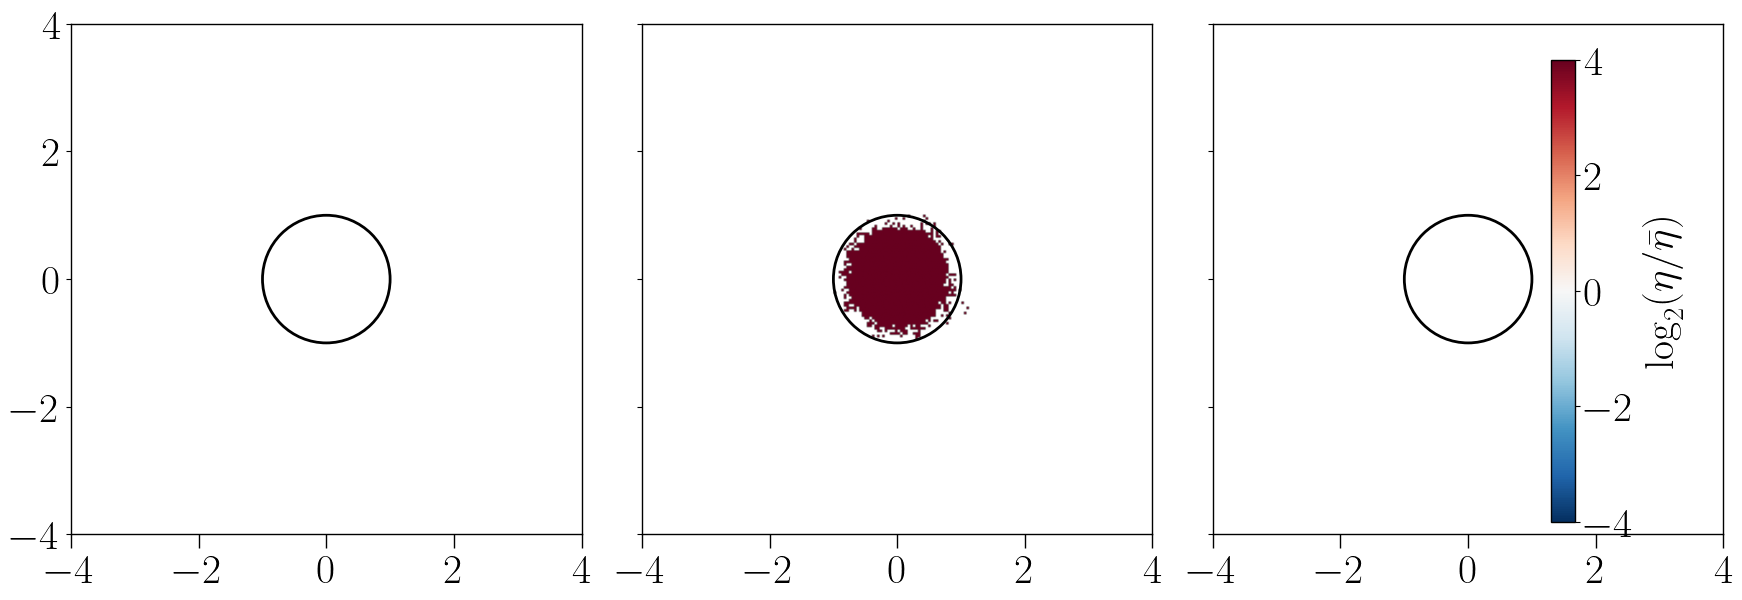

In [286]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
from matplotlib.patches import Circle

# Your real mask‐radius function
def mask_radius_for_mag(mag):
    return 1630./3600. * 1.396**(-mag)

# Bins and settings
mag_bins = [(8,12), (12,13), (13,16)]
nbins    = 200
r_ext    = 4.0
dr       = 0.06

# Precompute BG SkyCoord
cats = SkyCoord(ra=bg['RA'].values * u.deg,
                dec=bg['DEC'].values * u.deg)

fig, axes = plt.subplots(1, 3, figsize=(18,6), sharex=True, sharey=True)
for ax, (gmin, gmax) in zip(axes, mag_bins):
    # 1) select Gaia in this mag‐bin
    sel    = (gaia['phot_g_mean_mag'] >= gmin) & (gaia['phot_g_mean_mag'] < gmax)
    bright = gaia[sel]
    stars  = SkyCoord(ra=bright['ra'].values * u.deg,
                      dec=bright['dec'].values * u.deg)

    # 2) match to BG
    idx, _, _ = cats.match_to_catalog_sky(stars)

    # 3) compute offsets (rad)
    ra_bg, dec_bg = cats.ra.rad, cats.dec.rad
    ra_st, dec_st = stars[idx].ra.rad, stars[idx].dec.rad
    dRAc = (ra_bg - ra_st) * np.cos(dec_st)
    dDec =  dec_bg - dec_st

    # 4) mask‐radius (deg → arcsec)
    mags_idx  = bright['phot_g_mean_mag'].values[idx]
    R_deg     = mask_radius_for_mag(mags_idx)
    R_arcsec  = R_deg * 3600.0

    # 5) normalise
    x = (dRAc * 3600.0) / R_arcsec
    y = (dDec      * 3600.0) / R_arcsec

    # 6) clip to ±r_ext
    keep = (np.abs(x) <= r_ext) & (np.abs(y) <= r_ext)
    x2, y2 = x[keep], y[keep]

    # 7) real 2D histogram & density‐ratio
    H, xe, ye = np.histogram2d(
        x2, y2, bins=nbins,
        range=[[-r_ext, r_ext], [-r_ext, r_ext]]
    )
    Xc, Yc  = 0.5*(xe[:-1]+xe[1:]), 0.5*(ye[:-1]+ye[1:])
    XX, YY  = np.meshgrid(Xc, Yc)
    annmask = (np.sqrt(XX**2 + YY**2) > 1.1) & (np.sqrt(XX**2 + YY**2) < 4.0)
    eta_bar = H[annmask].mean()
    densrat = H / eta_bar

    # 8) plot with imshow
    im = ax.imshow(
        np.log2(densrat).T,
        origin='lower',
        extent=[-r_ext, r_ext, -r_ext, r_ext],
        cmap='RdBu_r', vmin=-4, vmax=+4,
        aspect='equal'
    )

    # 9) black circle & radial curves
    ax.add_patch(Circle((0,0),1,fill=False,lw=2,ec='k'))
    rad     = np.sqrt(x2**2 + y2**2)
    rbins   = np.arange(0, r_ext+dr, dr)
    rcent   = 0.5*(rbins[:-1]+rbins[1:])
    counts,_= np.histogram(rad, bins=rbins)
    areas    = np.pi*(rbins[1:]**2 - rbins[:-1]**2)
    log_eta  = np.log2((counts/areas)/eta_bar)
    ax.plot(rcent, log_eta, color='r', lw=2)
    ax.plot(log_eta, rcent, color='r', lw=2)

    ax.set_xlim(-r_ext,r_ext)
    ax.set_ylim(-r_ext,r_ext)
    # ax.set_title(f'{gmin} ≤ G < {gmax}')
    # ax.set_xlabel('ΔRA/R₍BS₎')
    # ax.set_ylabel('ΔDec/R₍BS₎')

# shared colourbar
fig.colorbar(im, ax=axes.ravel().tolist(),
             label=r'$\log_2(\eta/\bar\eta)$', fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()
